# Ok-k-mer

Use python310 conda environment

## Imports

In [2]:
import ok_k_mer

In [2]:
# import os
# import re
# import multiprocessing as mp
# from random import randint
# from random import sample
# from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40



In [3]:
# import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [4]:
import warnings
warnings.filterwarnings("ignore")


In [5]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Process/Load data

In [6]:
# Load merged_dfs
#
#aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
#bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
#caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
#chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
#cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
#neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'
#
#aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
#bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
#caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
#chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
#cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
#neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'
#
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = ok_k_mer.process_data(chlamydia_tree_path, chlamydia_dir_path)
# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = ok_k_mer.process_data(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = ok_k_mer.process_data(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = ok_k_mer.process_data(caldisericia_tree_path, caldisericia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = ok_k_mer.process_data(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = ok_k_mer.process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)
#
## Save each merged DataFrame to a CSV file
#aquificota_merged_df.to_csv('aquificota_merged_df.csv', index=False)
#bacillales_merged_df.to_csv('bacillales_merged_df.csv', index=False)
#caldisericia_merged_df.to_csv('caldisericia_merged_df.csv', index=False)
#chlamydia_merged_df.to_csv('chlamydia_merged_df.csv', index=False)
#cyano_merged_df.to_csv('cyano_merged_df.csv', index=False)
#neisseriaceae_merged_df.to_csv('neisseriaceae_merged_df.csv', index=False)

# Load each merged DataFrame
aquificota_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_merged_df.csv')
bacillales_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_merged_df.csv')
caldisericia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_merged_df.csv')
chlamydia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_merged_df.csv')
cyano_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_merged_df.csv')
neisseriaceae_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_merged_df.csv')

# Prepare a list of all available merged_dfs and their names
merged_df_datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

In [ ]:
# Load 1k data
#for name, merged_df in merged_df_datasets:
#    print(name)
#    M, (k, corr, pval) = ok_k_mer.initial_corr(merged_df, k_low=6, k_high=40)
#    np.save(f"{name}_1k_corr.npy", M)
#    print()

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_1k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_1k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_1k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_1k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_1k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_1k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_1k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [ ]:
# Load 2k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_2k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_2k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_2k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_slurm_tensor_2k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_2k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neis_slurm_tensor_2k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_2k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [ ]:
# Load 3k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_3k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_3k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_3k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_3k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_3k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_3k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = -1 * aquificota_grid
bacillales_grid    = -1 * bacillales_grid
caldisericia_grid  = -1 * caldisericia_grid
chlamydia_grid     = -1 * chlamydia_grid
cyano_grid         = -1 * cyano_grid
neisseriaceae_grid = -1 * neisseriaceae_grid

datasets_3k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]

In [ ]:
# Load Dashing intersection cardinality data

aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/intersection_cardinality'
bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/intersection_cardinality'
caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/intersection_cardinality'
chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/intersection_cardinality'
cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/intersection_cardinality'
neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/intersection_cardinality'

aquificota_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk'

# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_intersection_card_df = ok_k_mer.process_dashing_intersection_card(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_intersection_card_df = ok_k_mer.process_dashing_intersection_card(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_intersection_card_df = ok_k_mer.process_dashing_intersection_card(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_intersection_card_df = ok_k_mer.process_dashing_intersection_card(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_intersection_card_df = ok_k_mer.process_dashing_intersection_card(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_intersection_card_df = ok_k_mer.process_dashing_intersection_card(neisseriaceae_tree_path, neisseriaceae_dir_path)

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in cardinality_datasets:
    # df.to_csv(f"{name}_card.csv")

# LOAD csvs
aquificota_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_card_df.csv')
bacillales_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_card_df.csv')
caldisericia_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_card_df.csv')
chlamydia_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_card_df.csv')
cyano_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_card_df.csv')
neisseriaceae_intersection_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_card_df.csv')

# Prepare a list of all available merged_dfs and their names
intersection_cardinality_datasets = [
    ("Aquificota", aquificota_intersection_card_df),
    ("Bacillales", bacillales_intersection_card_df),
    ("Caldisericia", caldisericia_intersection_card_df),
    ("Chlamydia", chlamydia_intersection_card_df),
    ("Cyano", cyano_intersection_card_df),
    ("Neisseriaceae", neisseriaceae_intersection_card_df),
]

In [ ]:
# Load KMC3 union cardinality data

aquificota_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/union_cardinality_kmc'
bacillales_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/union_cardinality_kmc'
caldisericia_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/union_cardinality_kmc'
chlamydia_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/union_cardinality_kmc'
cyano_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/union_cardinality_kmc'
neisseriaceae_dir_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/union_cardinality_kmc'

aquificota_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/p__Aquificota.nwk'
bacillales_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/o__Bacillales_A.nwk'
caldisericia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/c__Caldisericia.nwk'
chlamydia_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/o__Chlamydiales.nwk'
cyano_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/o__Cyanobacteriales.nwk'
neisseriaceae_tree_path = '/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/f__Neisseriaceae.nwk'

# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_card_df = ok_k_mer.process_kmc_union_card(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_card_df = ok_k_mer.process_kmc_union_card(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_card_df = ok_k_mer.process_kmc_union_card(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_card_df = ok_k_mer.process_kmc_union_card(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_card_df = ok_k_mer.process_kmc_union_card(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_card_df = ok_k_mer.process_kmc_union_card(neisseriaceae_tree_path, neisseriaceae_dir_path)

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in union_cardinality_datasets:
    # df.to_csv(f"{name}_union_card.csv")

aquificota_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/aquificota/union_cardinality_kmc/aquificota_union_card_df.csv')
bacillales_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/bacillales/union_cardinality_kmc/bacillales_union_card_df.csv')
caldisericia_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/caldisericia/union_cardinality_kmc/caldisericia_union_card_df.csv')
chlamydia_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/chlamydiales/union_cardinality_kmc/chlamydia_union_card_df.csv')
cyano_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/cyanobacteriales/union_cardinality_kmc/cyano_union_card_df.csv')
neisseriaceae_union_card_df = pd.read_csv('/vast/blangme2/sjhwang/ok_k_mer_data/neisseriaceae/union_cardinality_kmc/neisseriaceae_union_card_df.csv')

# Prepare a list of all available merged_dfs and their names
union_cardinality_datasets = [
    ("Aquificota", aquificota_union_card_df),
    ("Bacillales", bacillales_union_card_df),
    ("Caldisericia", caldisericia_union_card_df),
    ("Chlamydia", chlamydia_union_card_df),
    ("Cyano", cyano_union_card_df),
    ("Neisseriaceae", neisseriaceae_union_card_df),
]



## Make shared cmap

In [ ]:
# cmap_dict = build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)
cmap_dict = ok_k_mer.build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)


In [ ]:
# Optinally: visualize the cmap
for name, (cmap, vmax) in cmap_dict.items():
    print(name)
    gradient = np.linspace(0, vmax, 1000).reshape(1, -1)
    fig, ax = plt.subplots(figsize=(6, 1))
    ax.imshow(gradient, aspect='auto', cmap=cmap)
    ax.set_axis_off()
    plt.title(f"Colormap: {name}")
    plt.show()

## Grid search and heatmaps on (one to three) k-mers

### One k-mer

In [ ]:
# Run full grid search
for name, df in datasets_1k:
    print(name)
    ok_k_mer.plot_1k_colorbar_corr(name, df, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
    print()


### Two k-mers


In [ ]:
# Run full grid search
for name, results_matrix in datasets_2k:
    print(name)
    results_matrix = np.abs(results_matrix)
    # results_matrix, min_val, k1_min, k2_min, w_min, min_val = ok_k_mer.run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)   # run grid search, now is a slurm script
    ok_k_mer.plot_2k_grid_joint_corr_weight(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
    # ok_k_mer.plot_2k_grid_corr(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
    # ok_k_mer.plot_2k_grid_weights(name, results_matrix, k_low=6, k_high=40, w_low=0, w_high=1, w_step=0.05)
    print()


### Three k-mers

In [ ]:
# Run across all datasets

s = 2 # s = 3
k_low = 6
k_high = 40

# Run 3-kmer grid search
for name, grid_df, k_best in datasets_3k:
    print(name, k_best)
    results = ok_k_mer.plot_3k_grid_corr(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name])
    results_grid_corr = ok_k_mer.plot_3k_grid_joint_corr_weight(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name], w_low=0, w_high=1, w_step=0.10)
    print()


## Plot k-mer cardinality
f(G1, G2, k) = G1(k) U G2(k) / 4**k


In [22]:

# Prepare a list of all available merged_dfs and their names
union_cardinality_datasets = [
    ("Aquificota", aquificota_union_card_df),
    ("Bacillales", bacillales_union_card_df),
    ("Caldisericia", caldisericia_union_card_df),
    ("Chlamydia", chlamydia_union_card_df),
    ("Cyano", cyano_union_card_df),
    ("Neisseriaceae", neisseriaceae_union_card_df),
]



In [23]:
# union_cardinality_datasets
len(union_cardinality_datasets)

6

Plotting k-mer cardinality for Aquificota


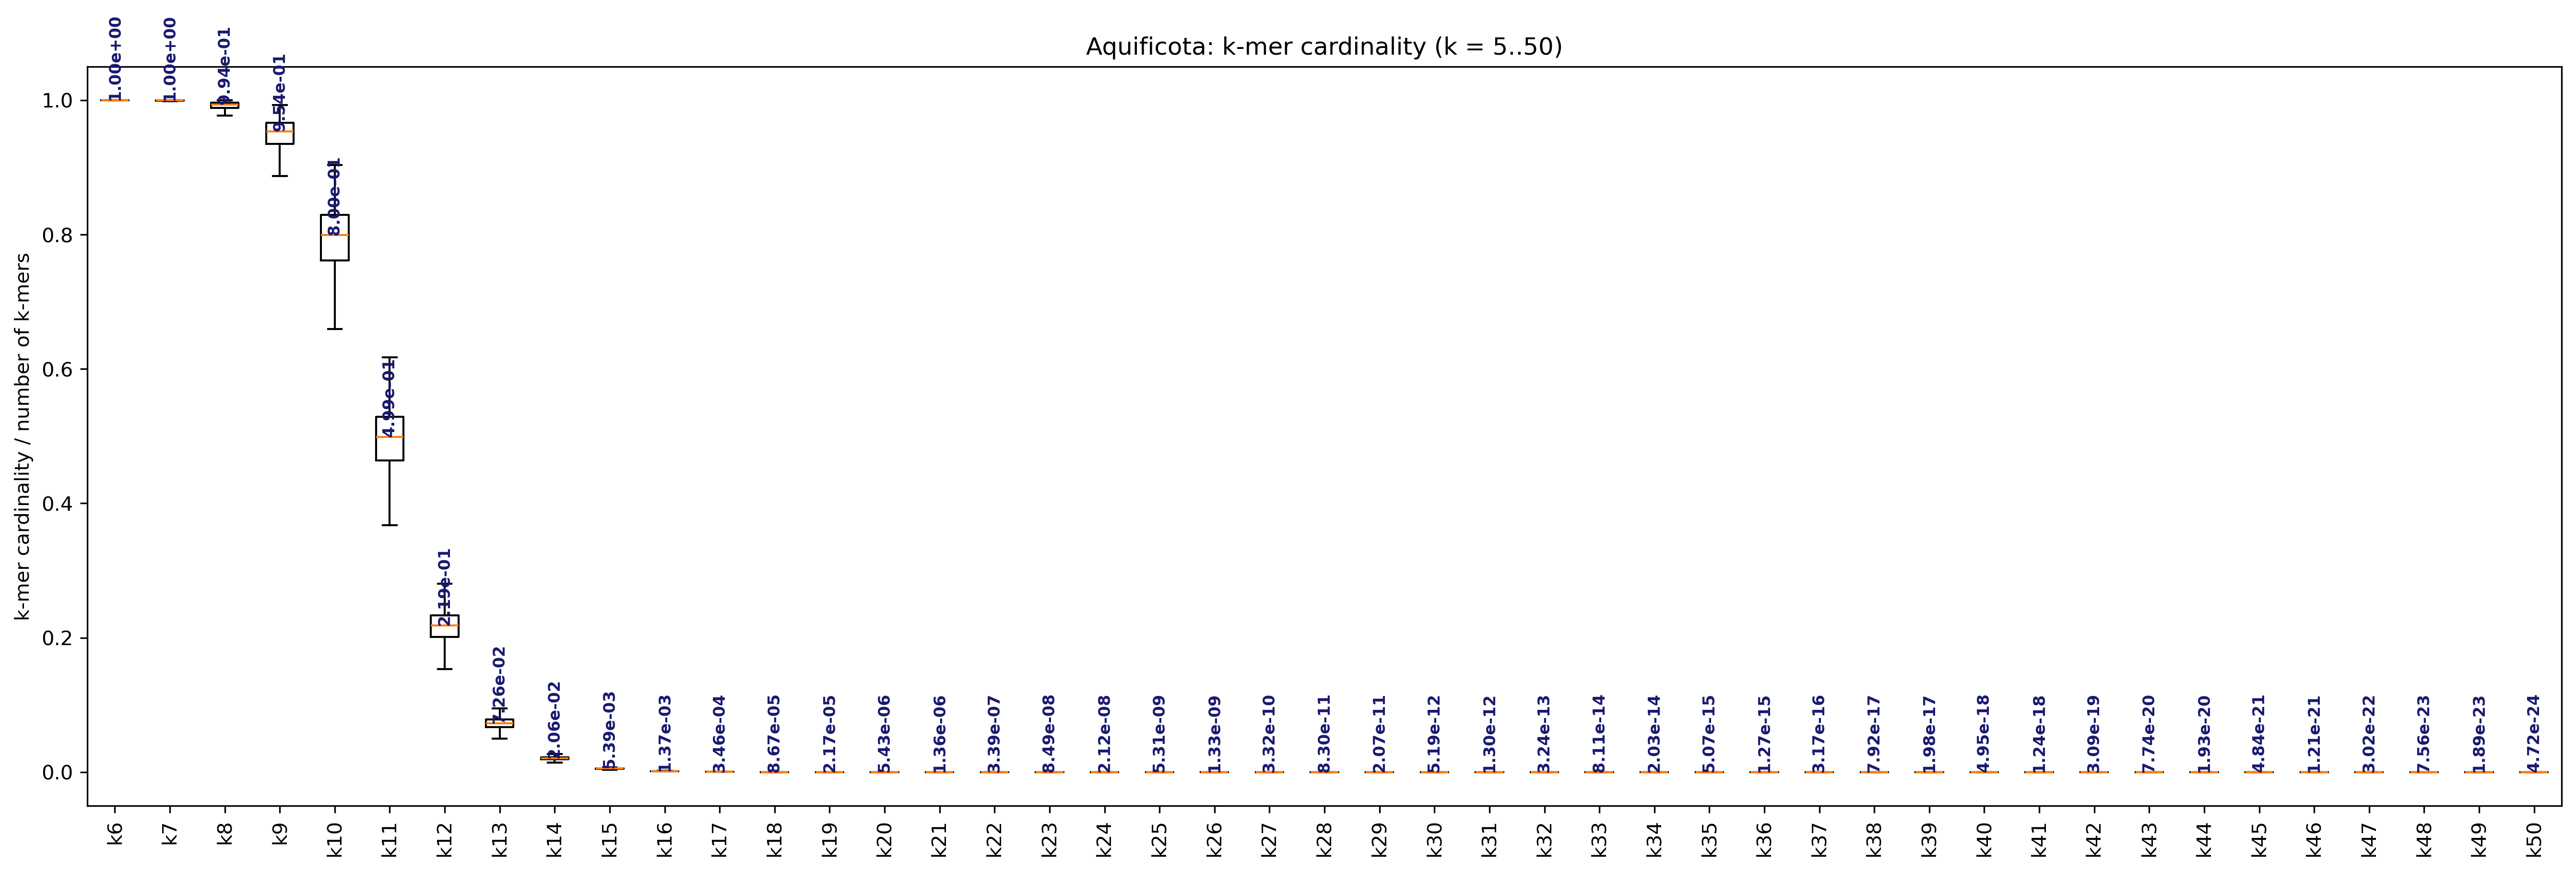

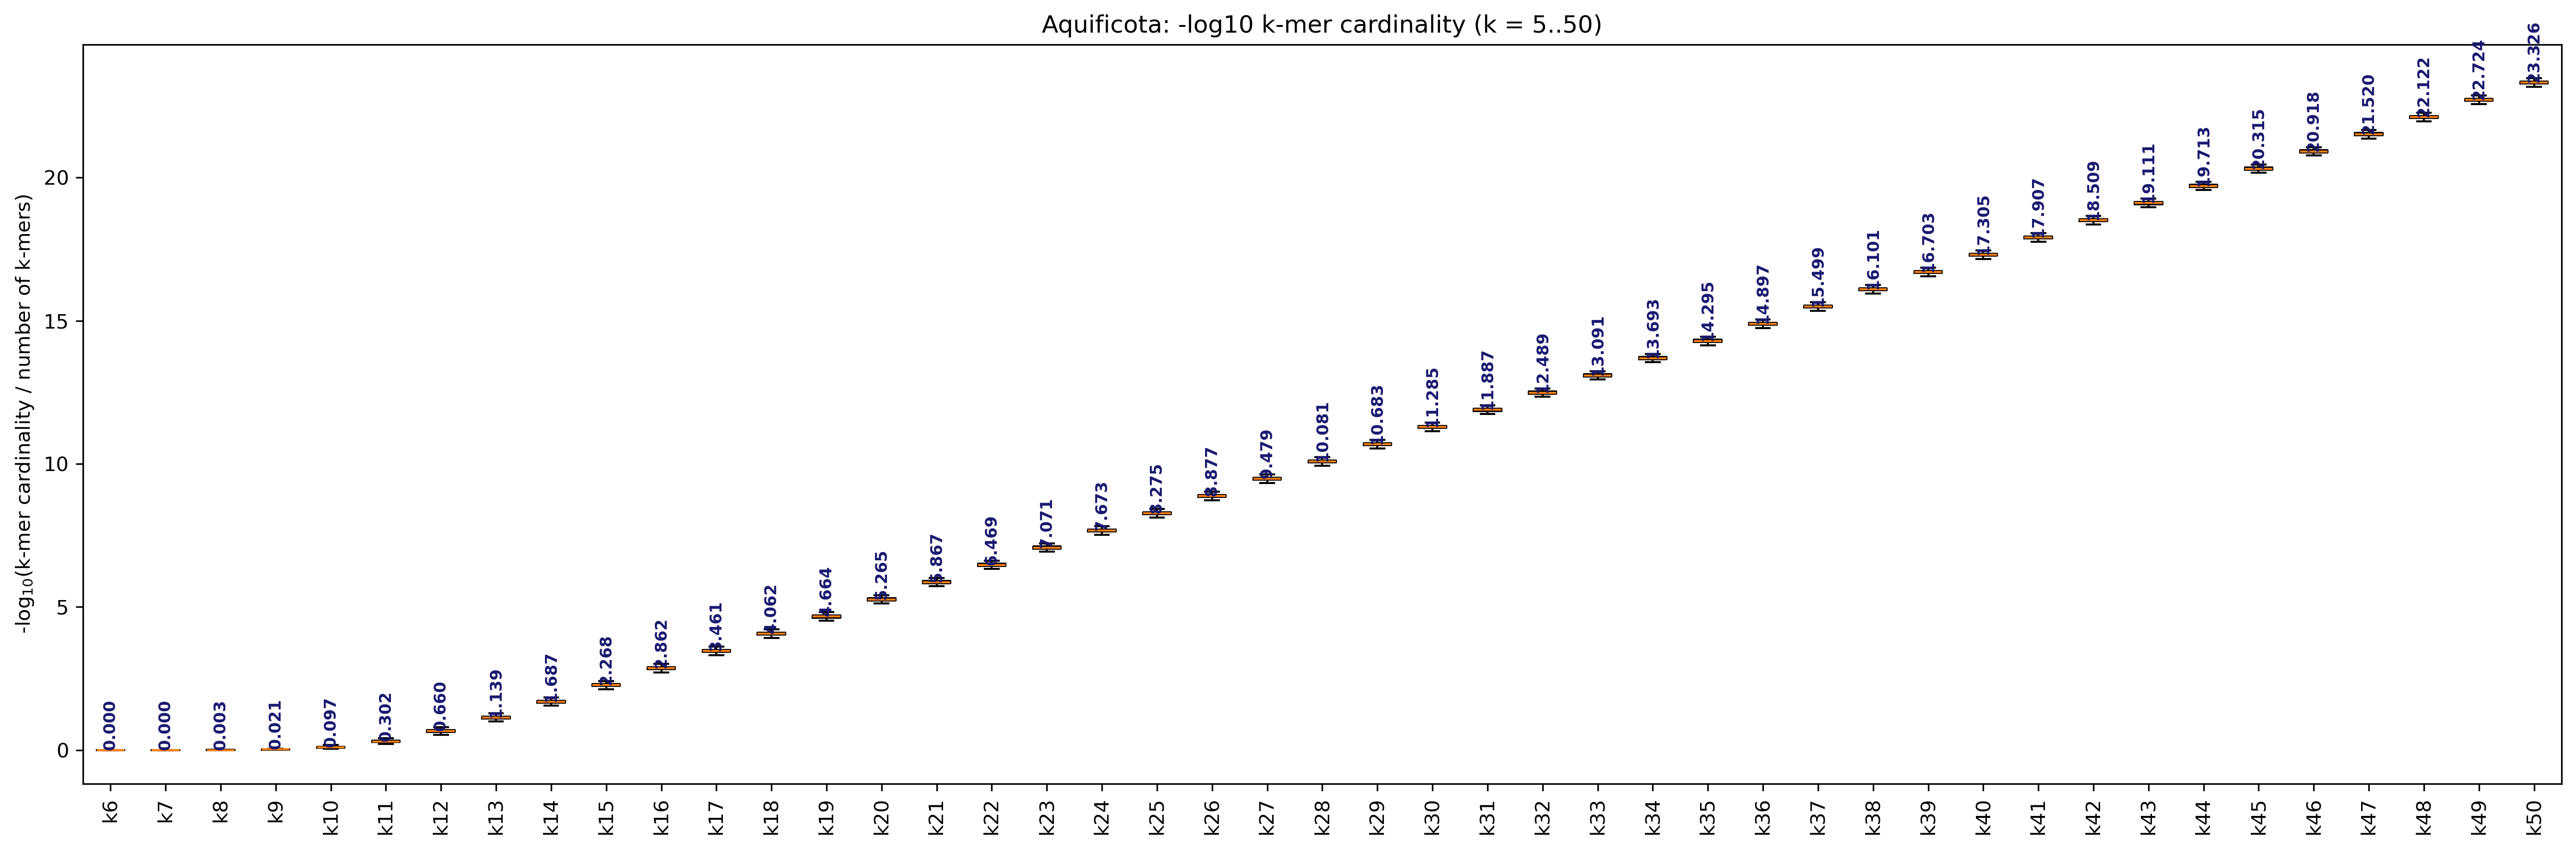


Plotting k-mer cardinality for Bacillales


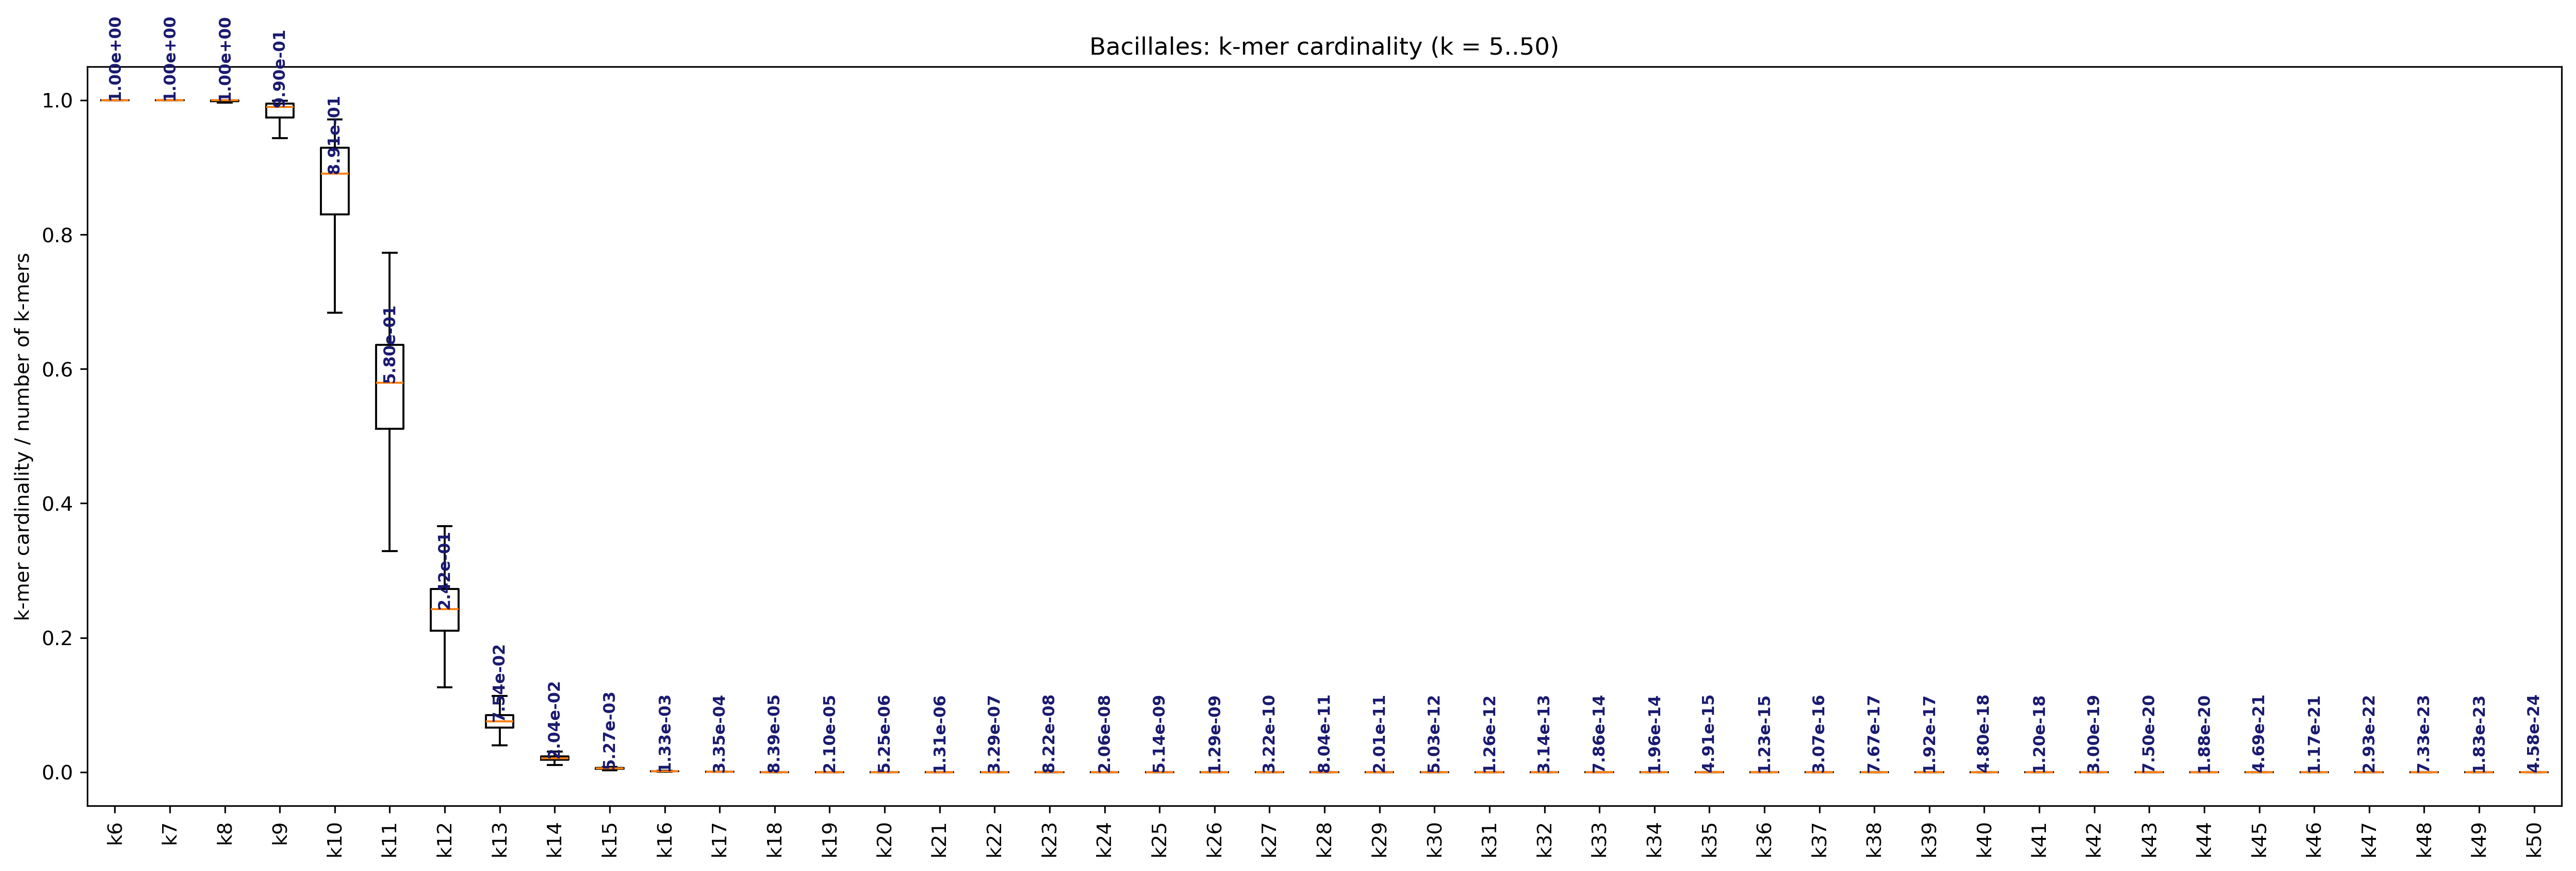

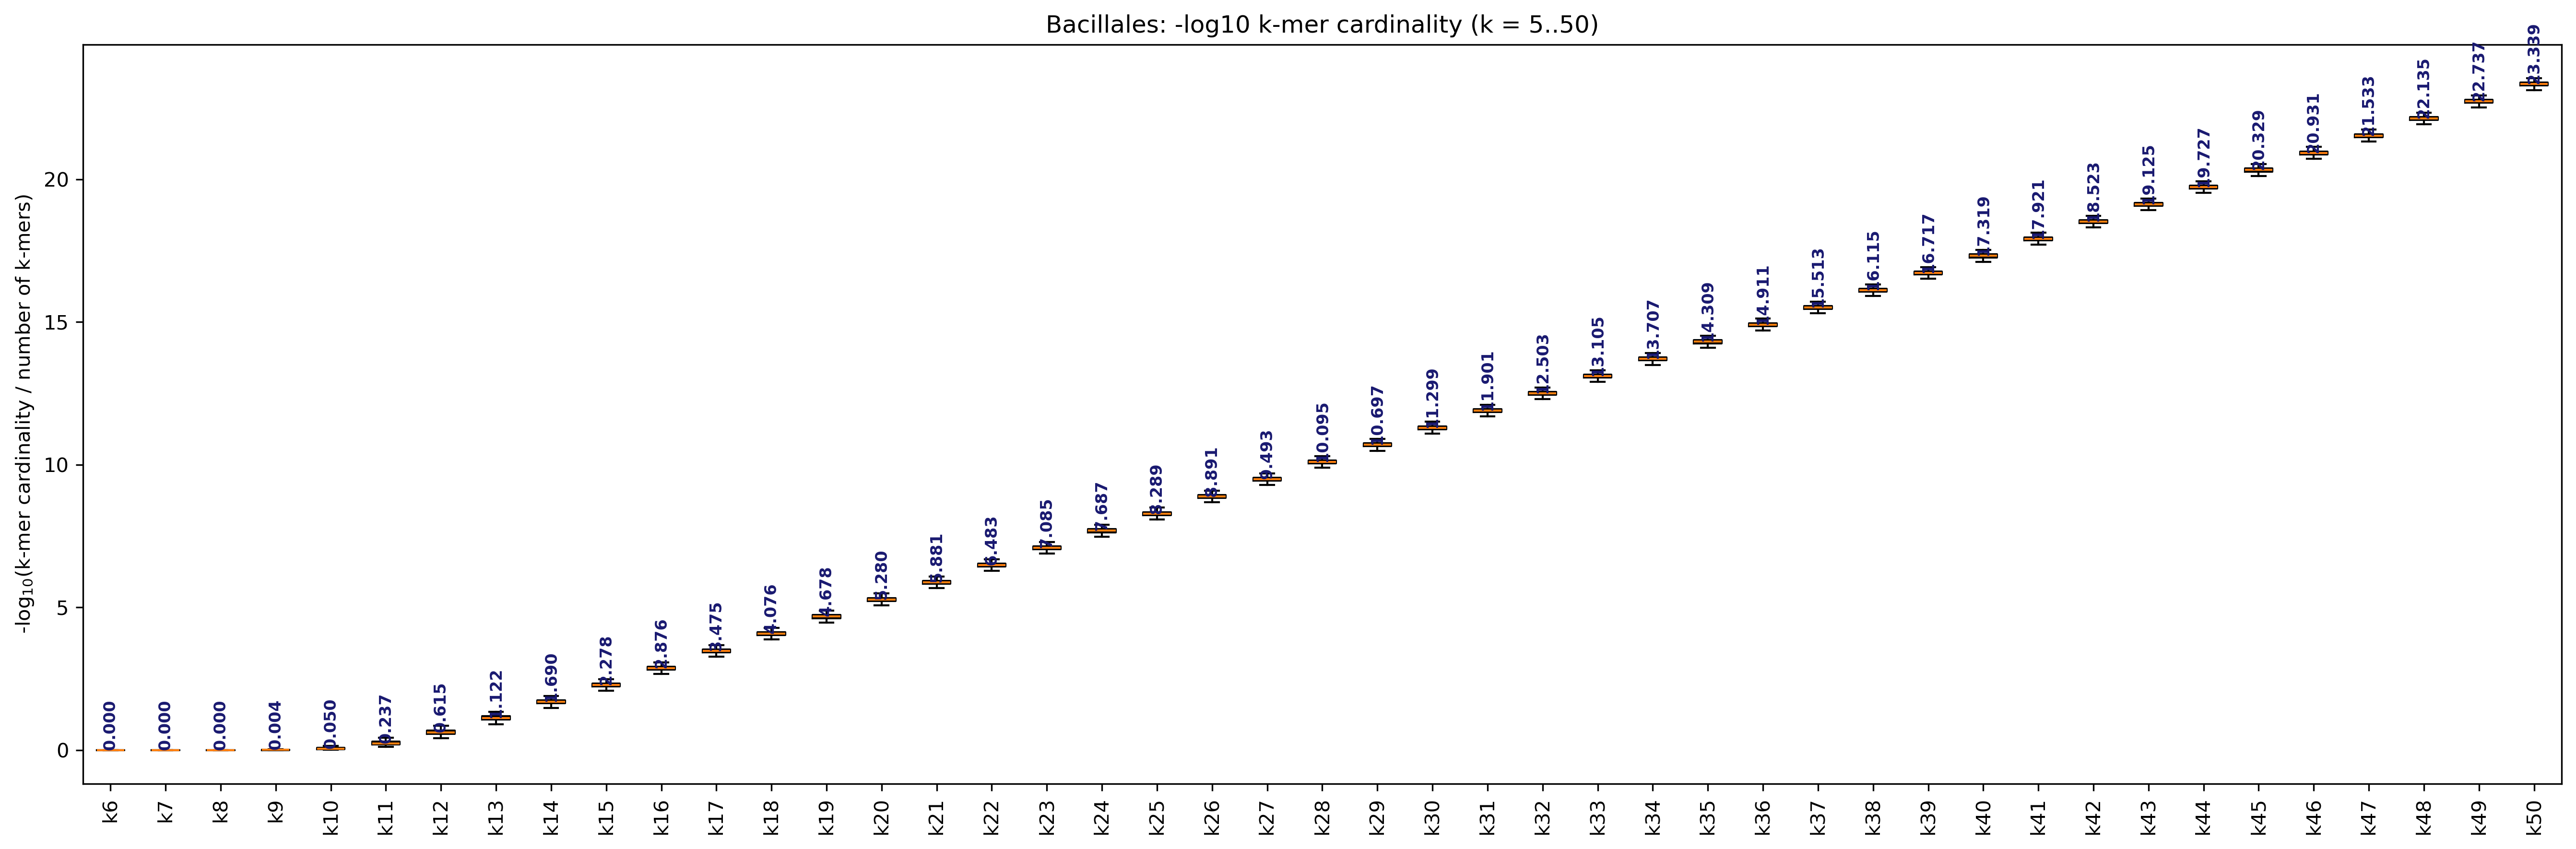


Plotting k-mer cardinality for Caldisericia


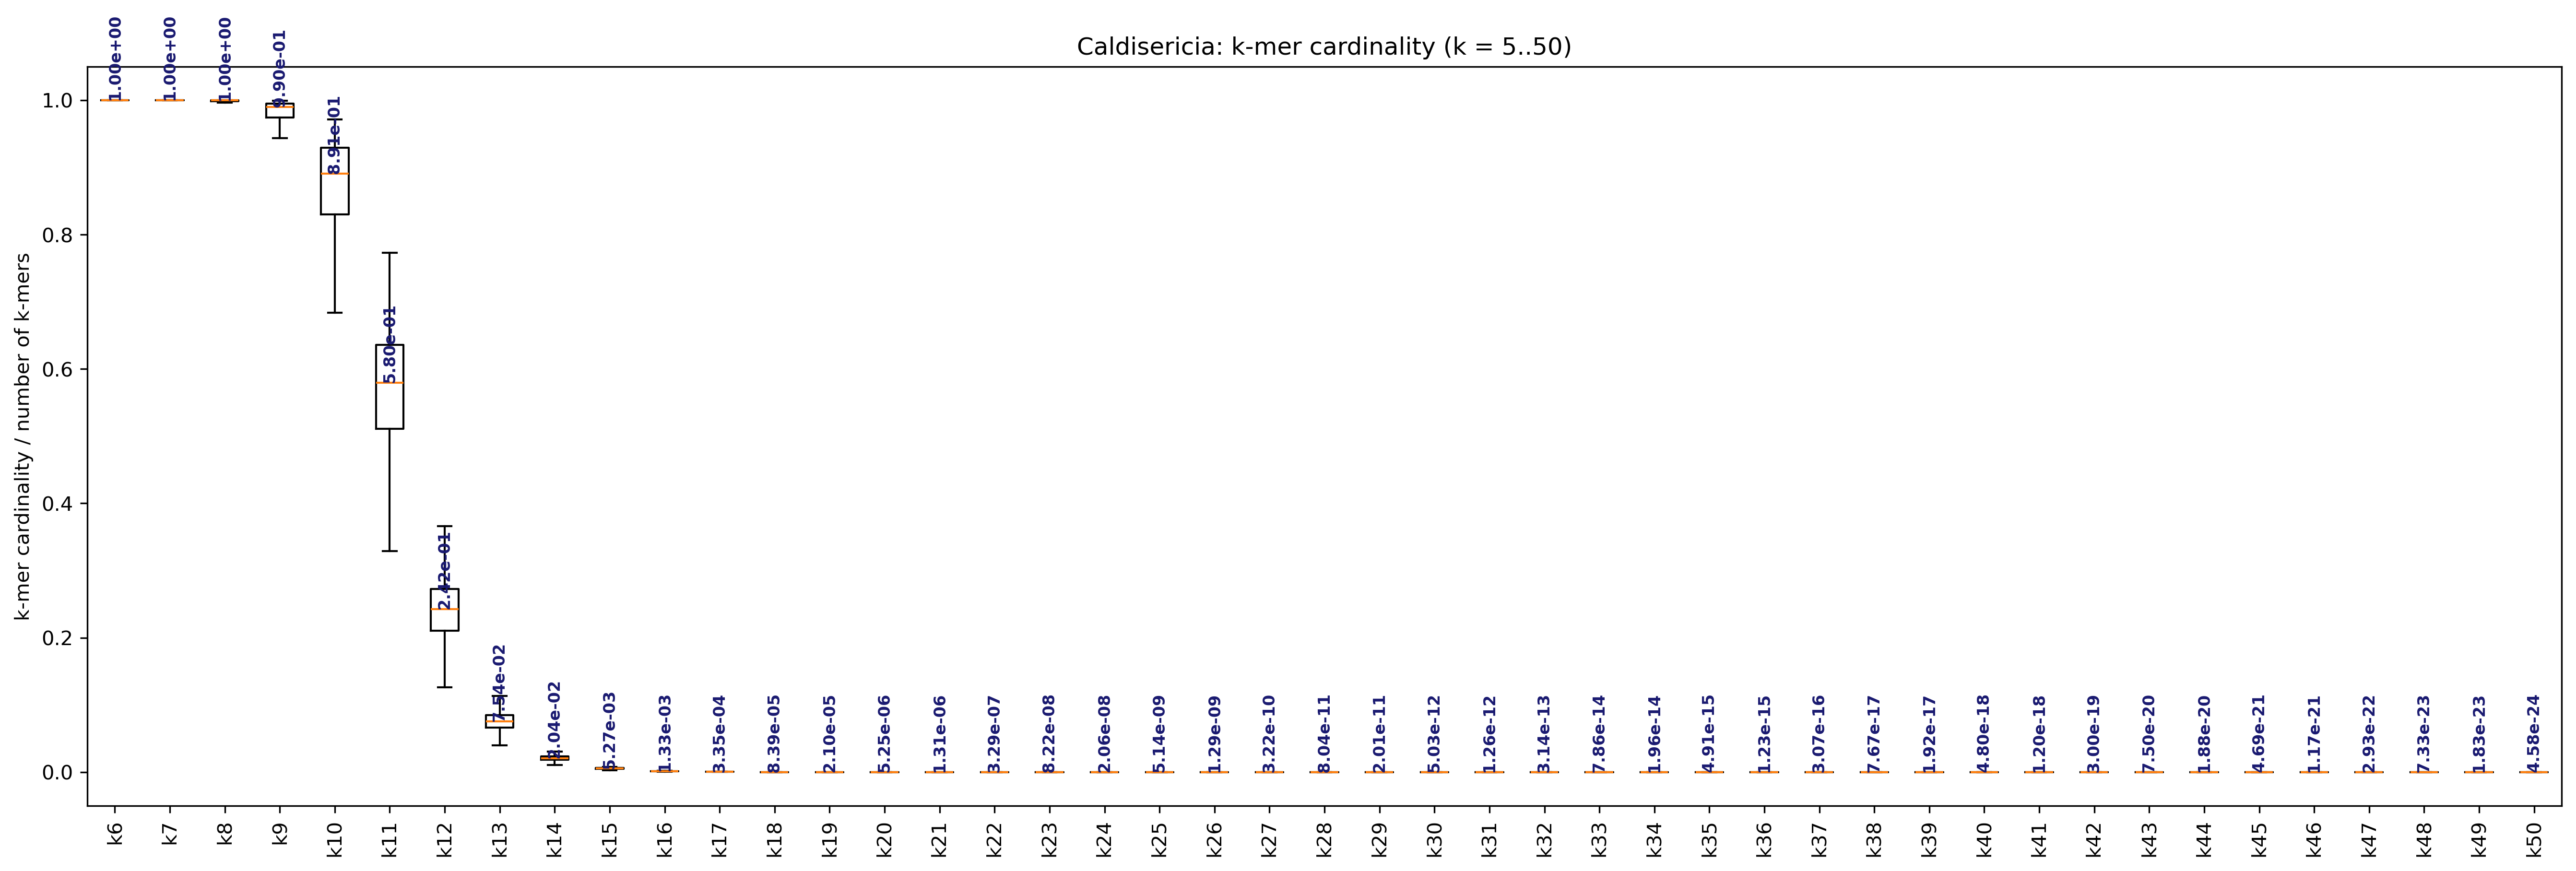

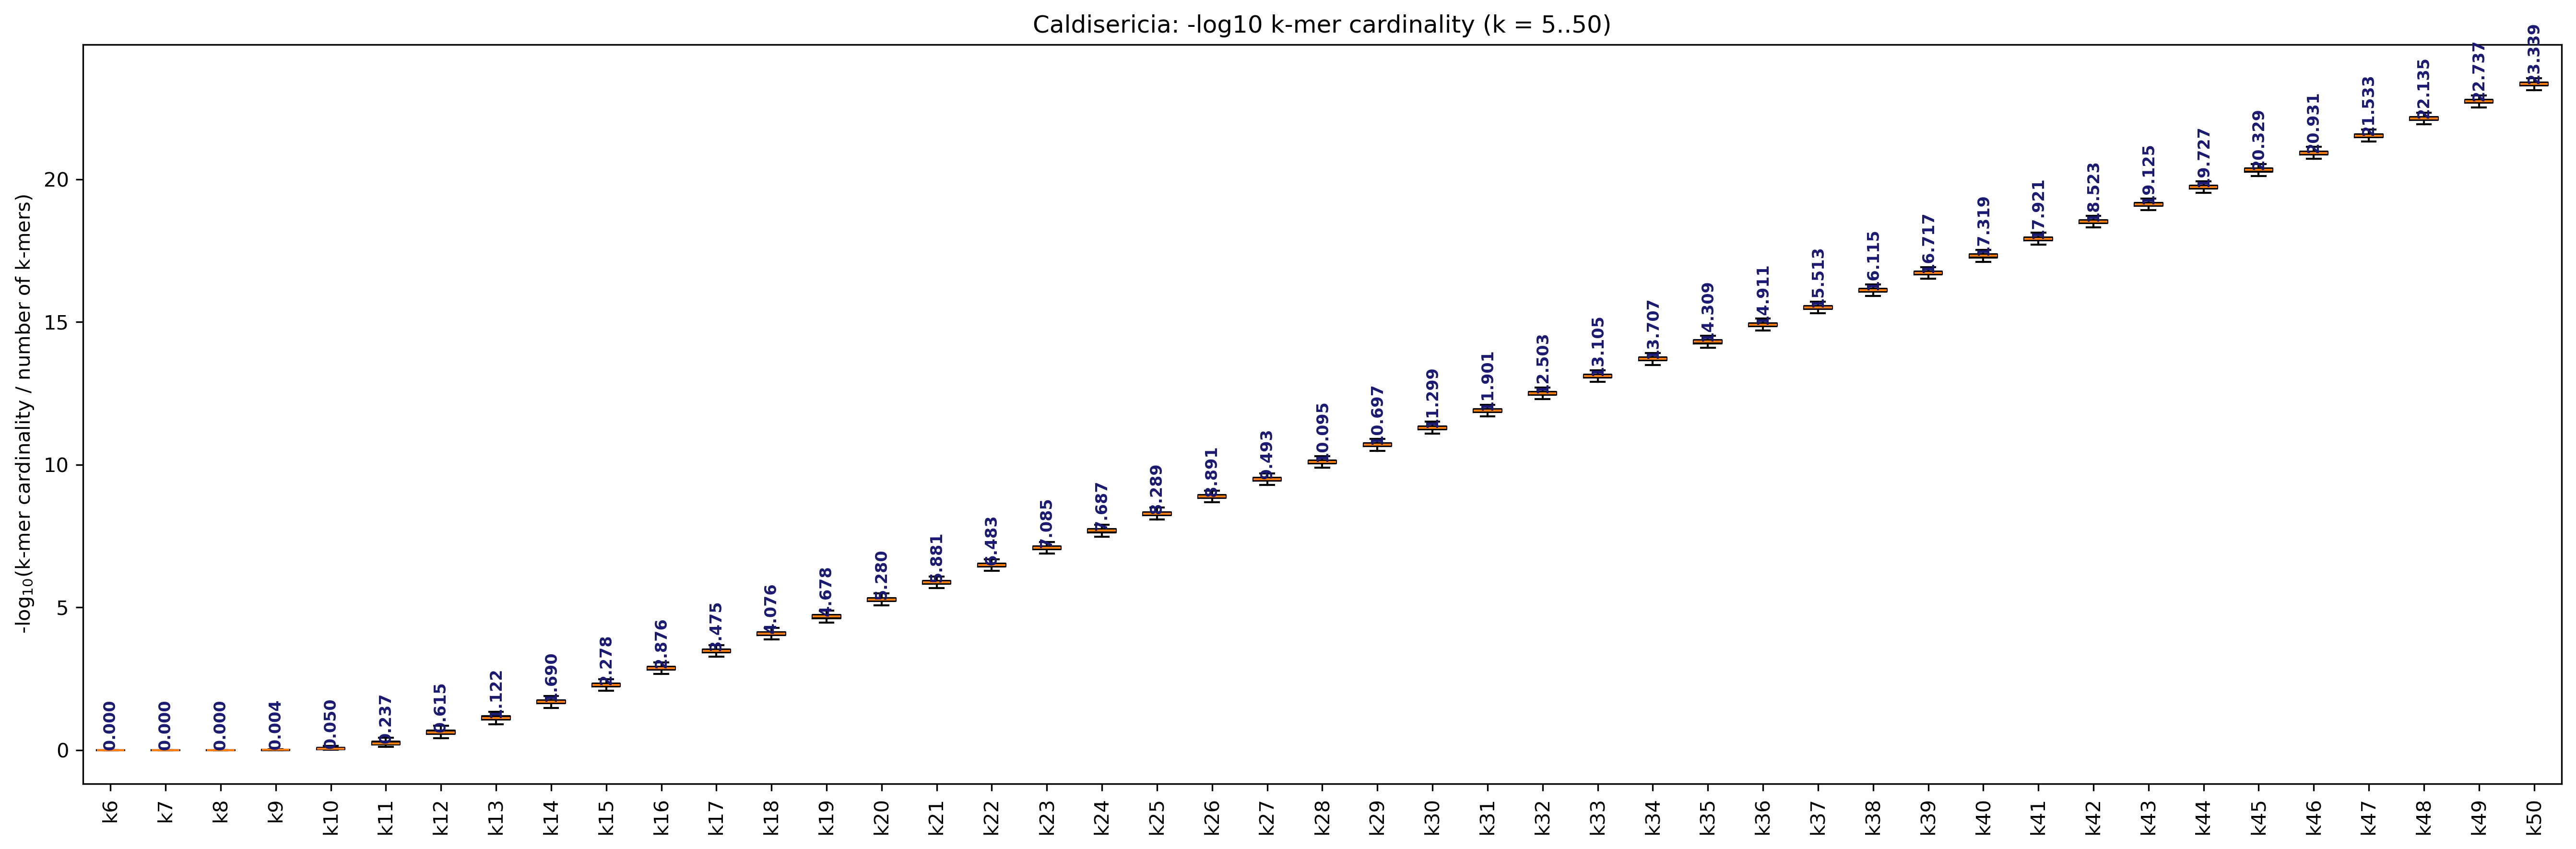


Plotting k-mer cardinality for Chlamydia


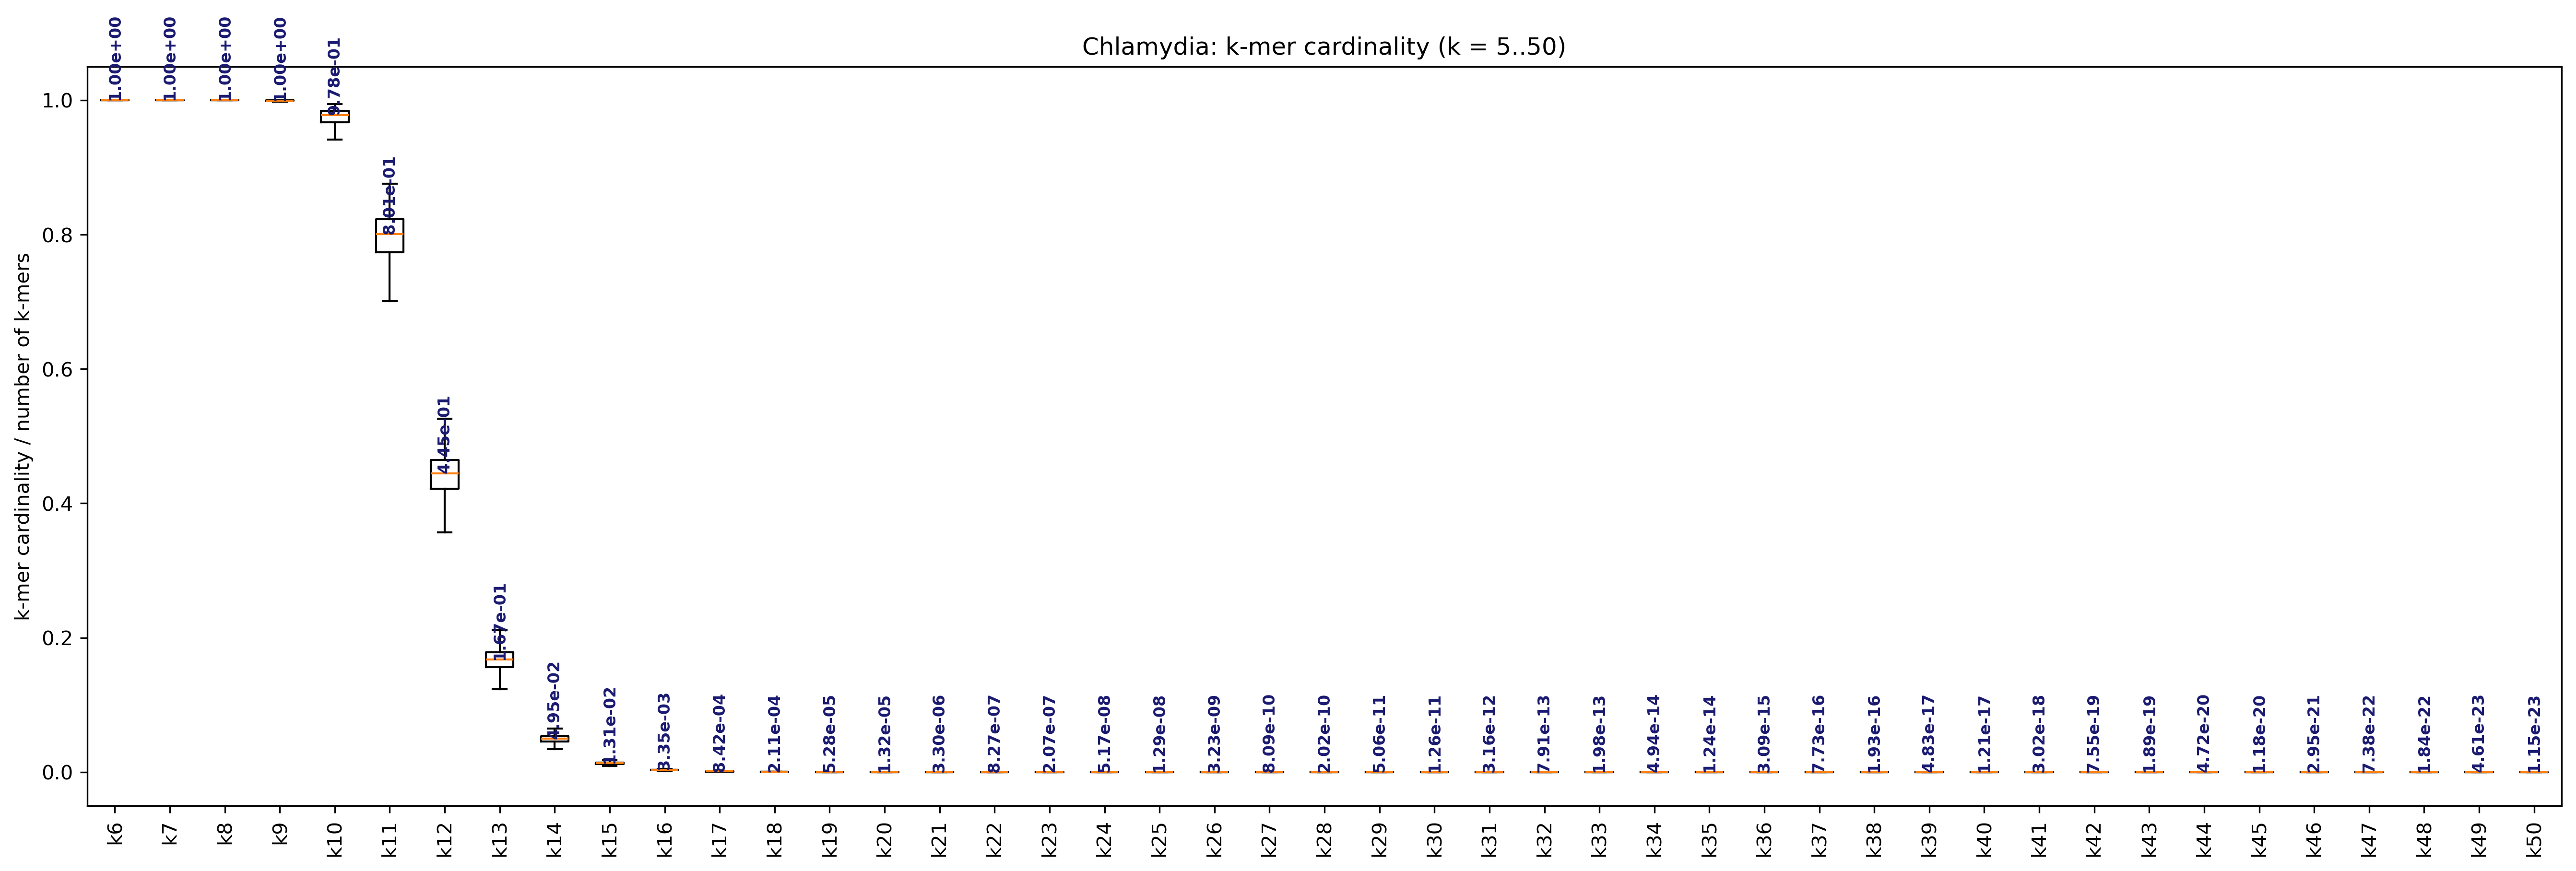

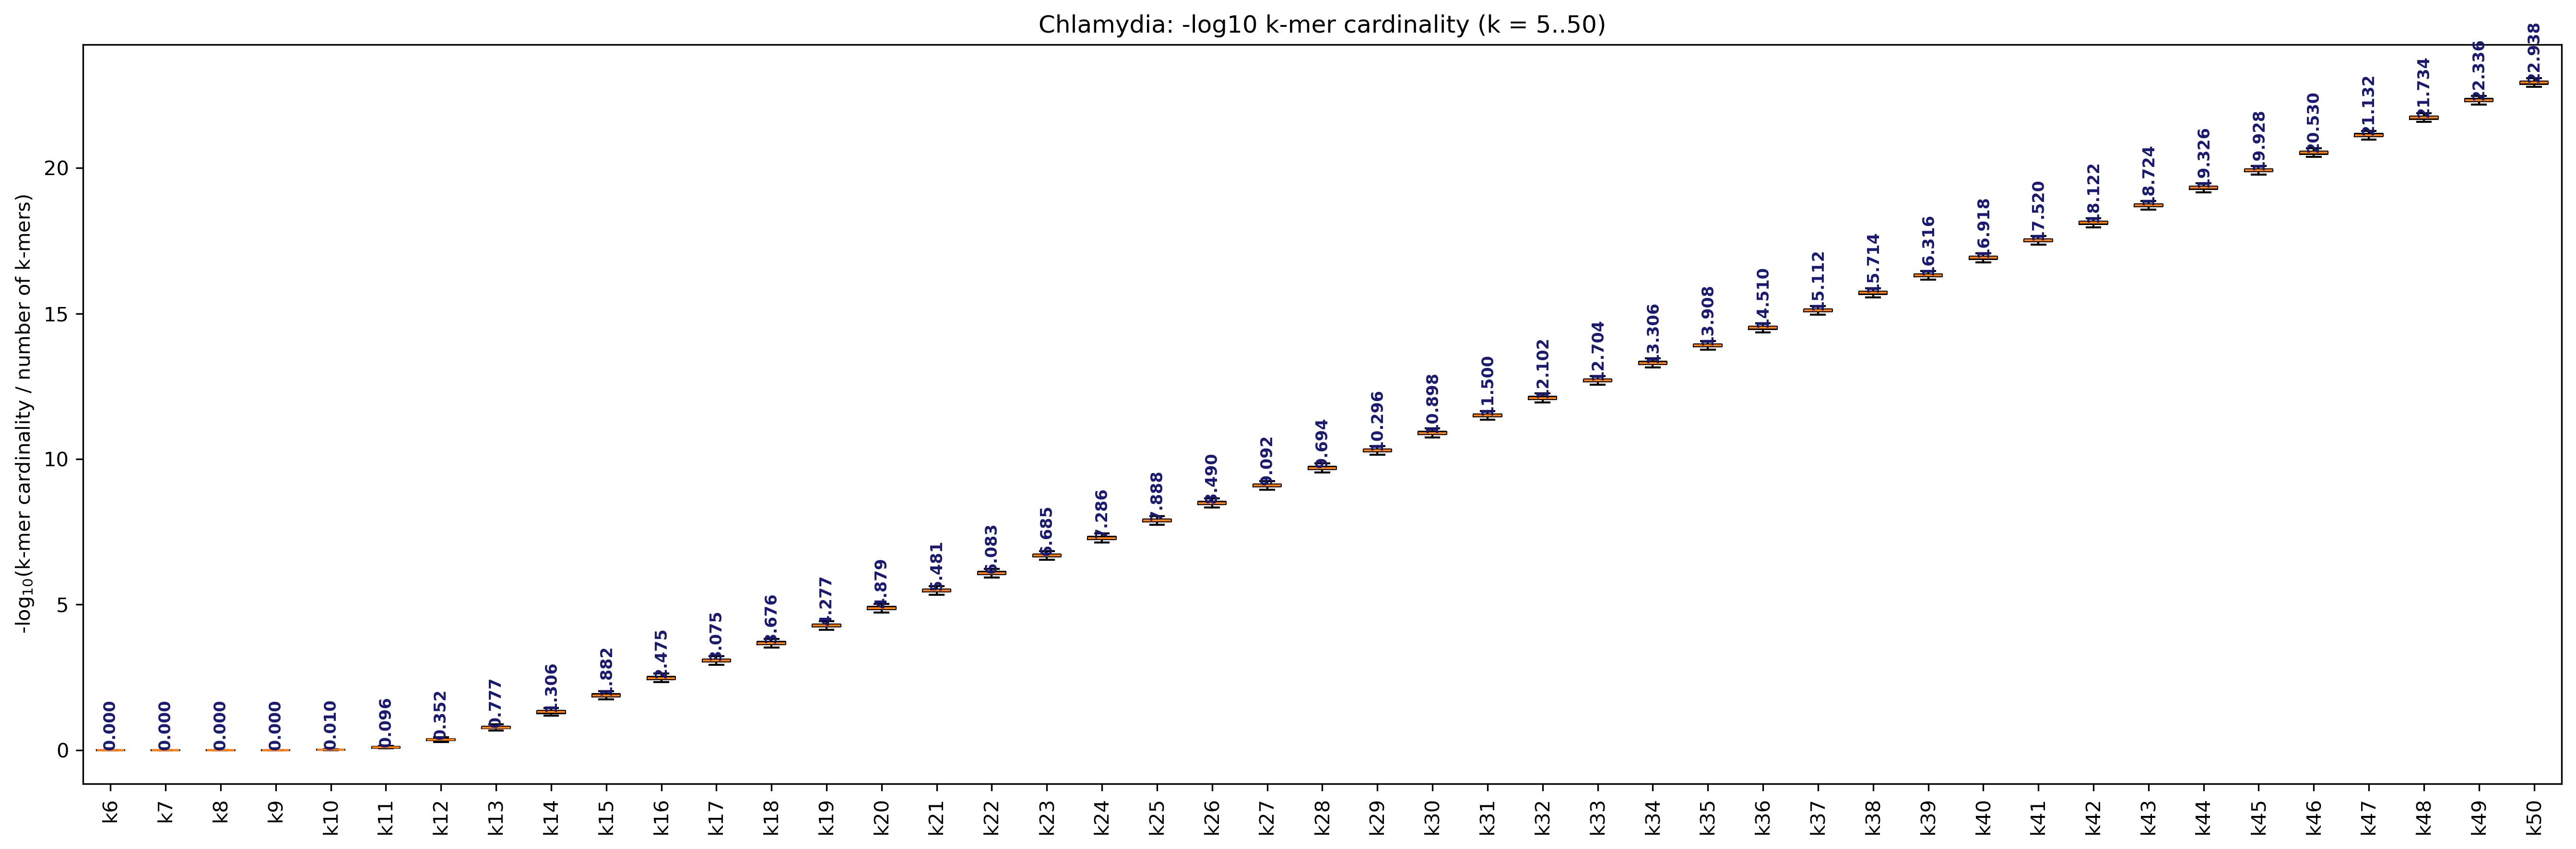


Plotting k-mer cardinality for Cyano


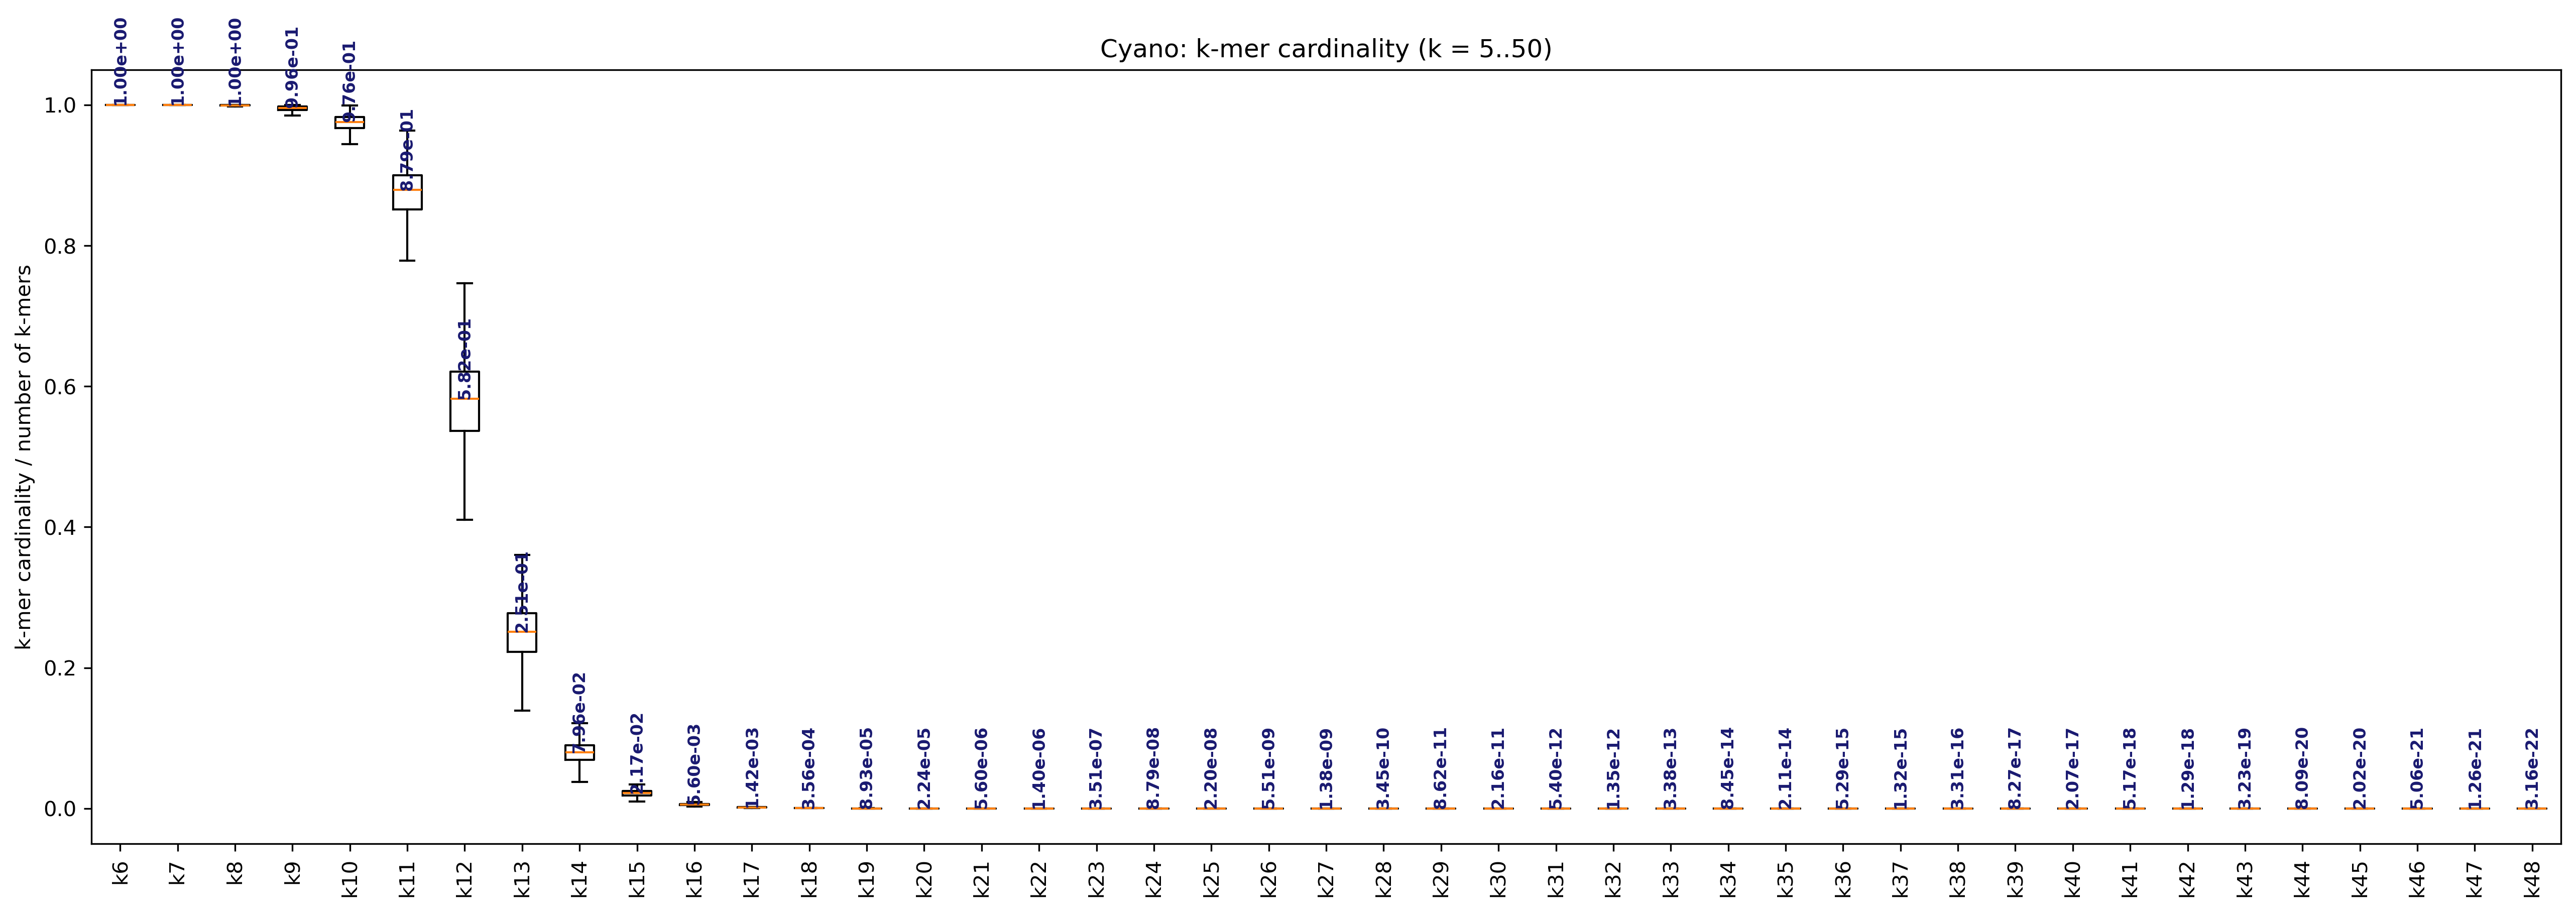

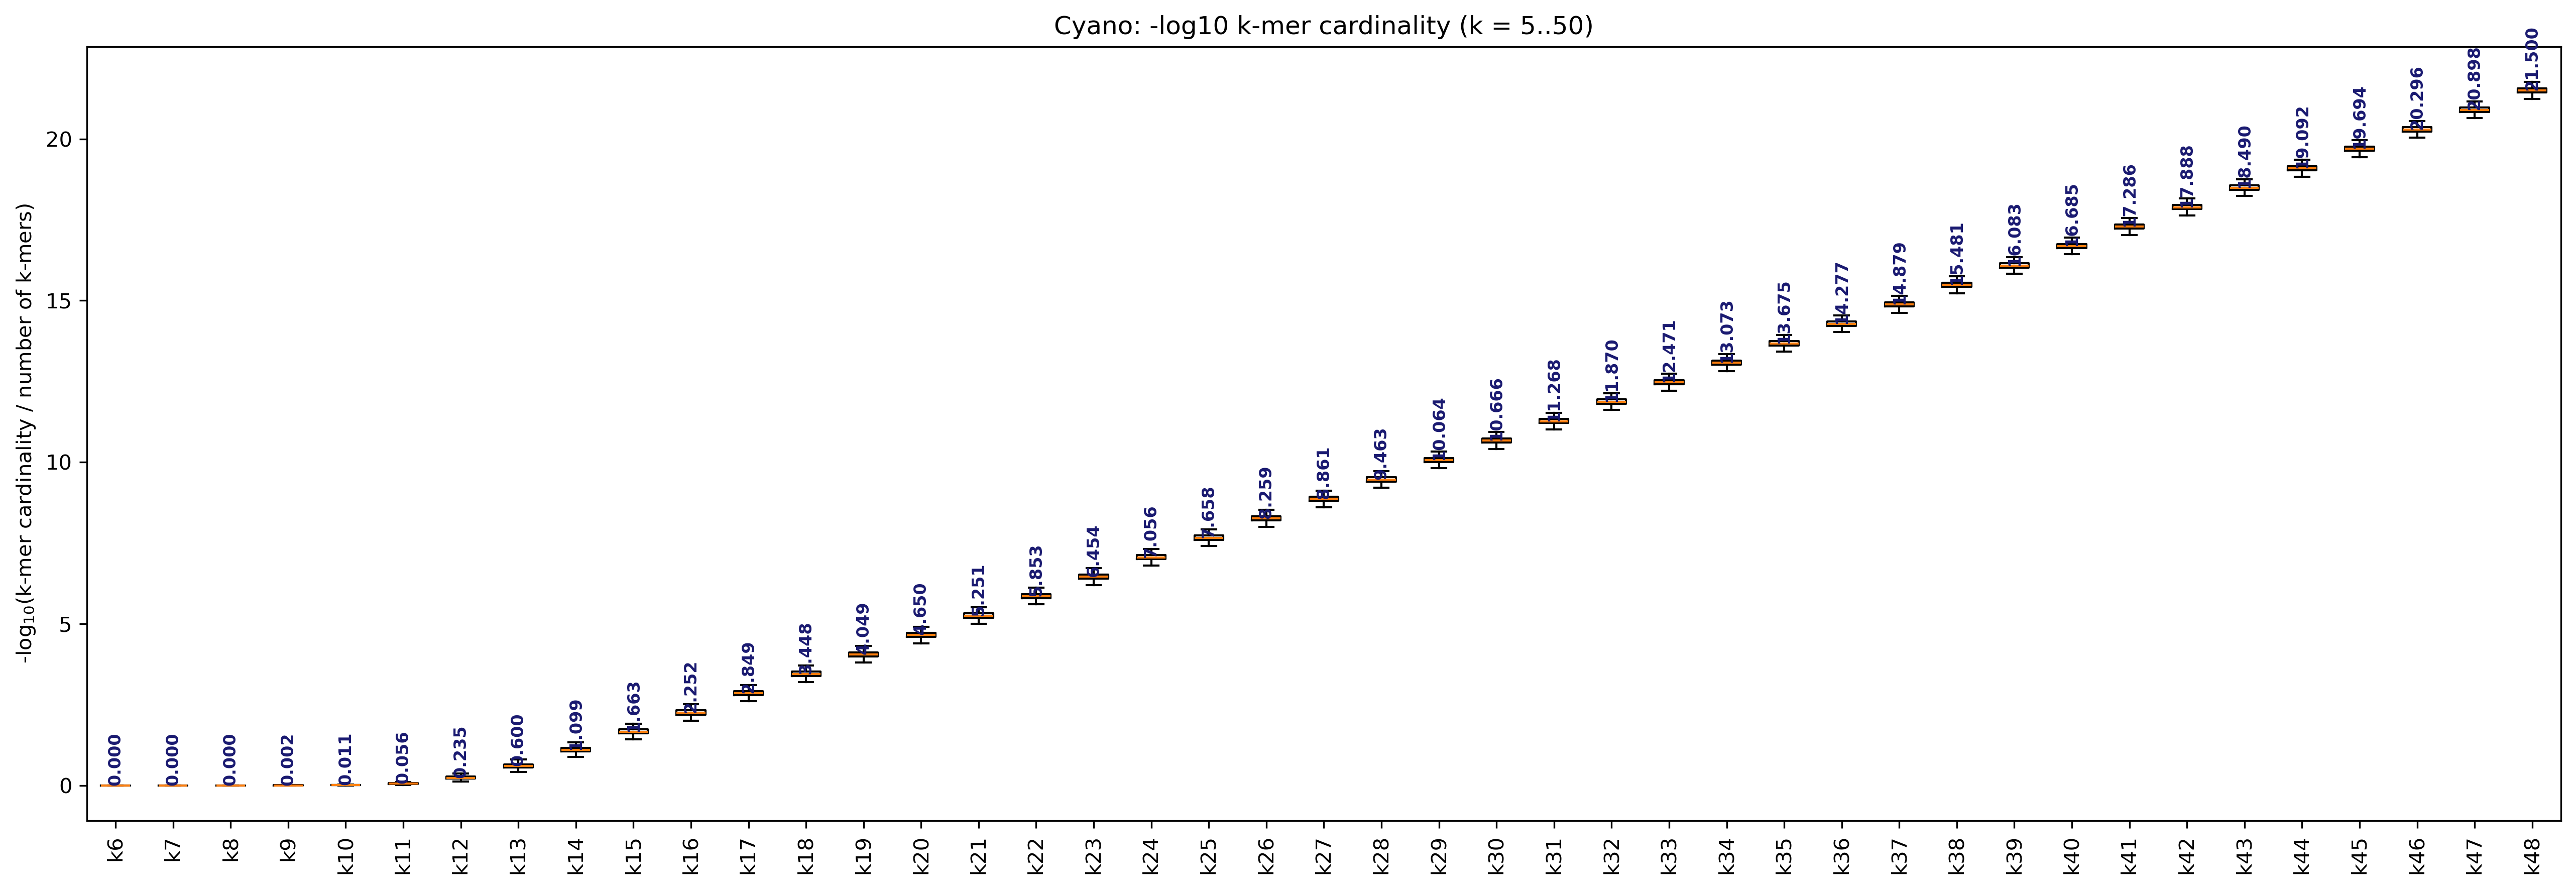


Plotting k-mer cardinality for Neisseriaceae


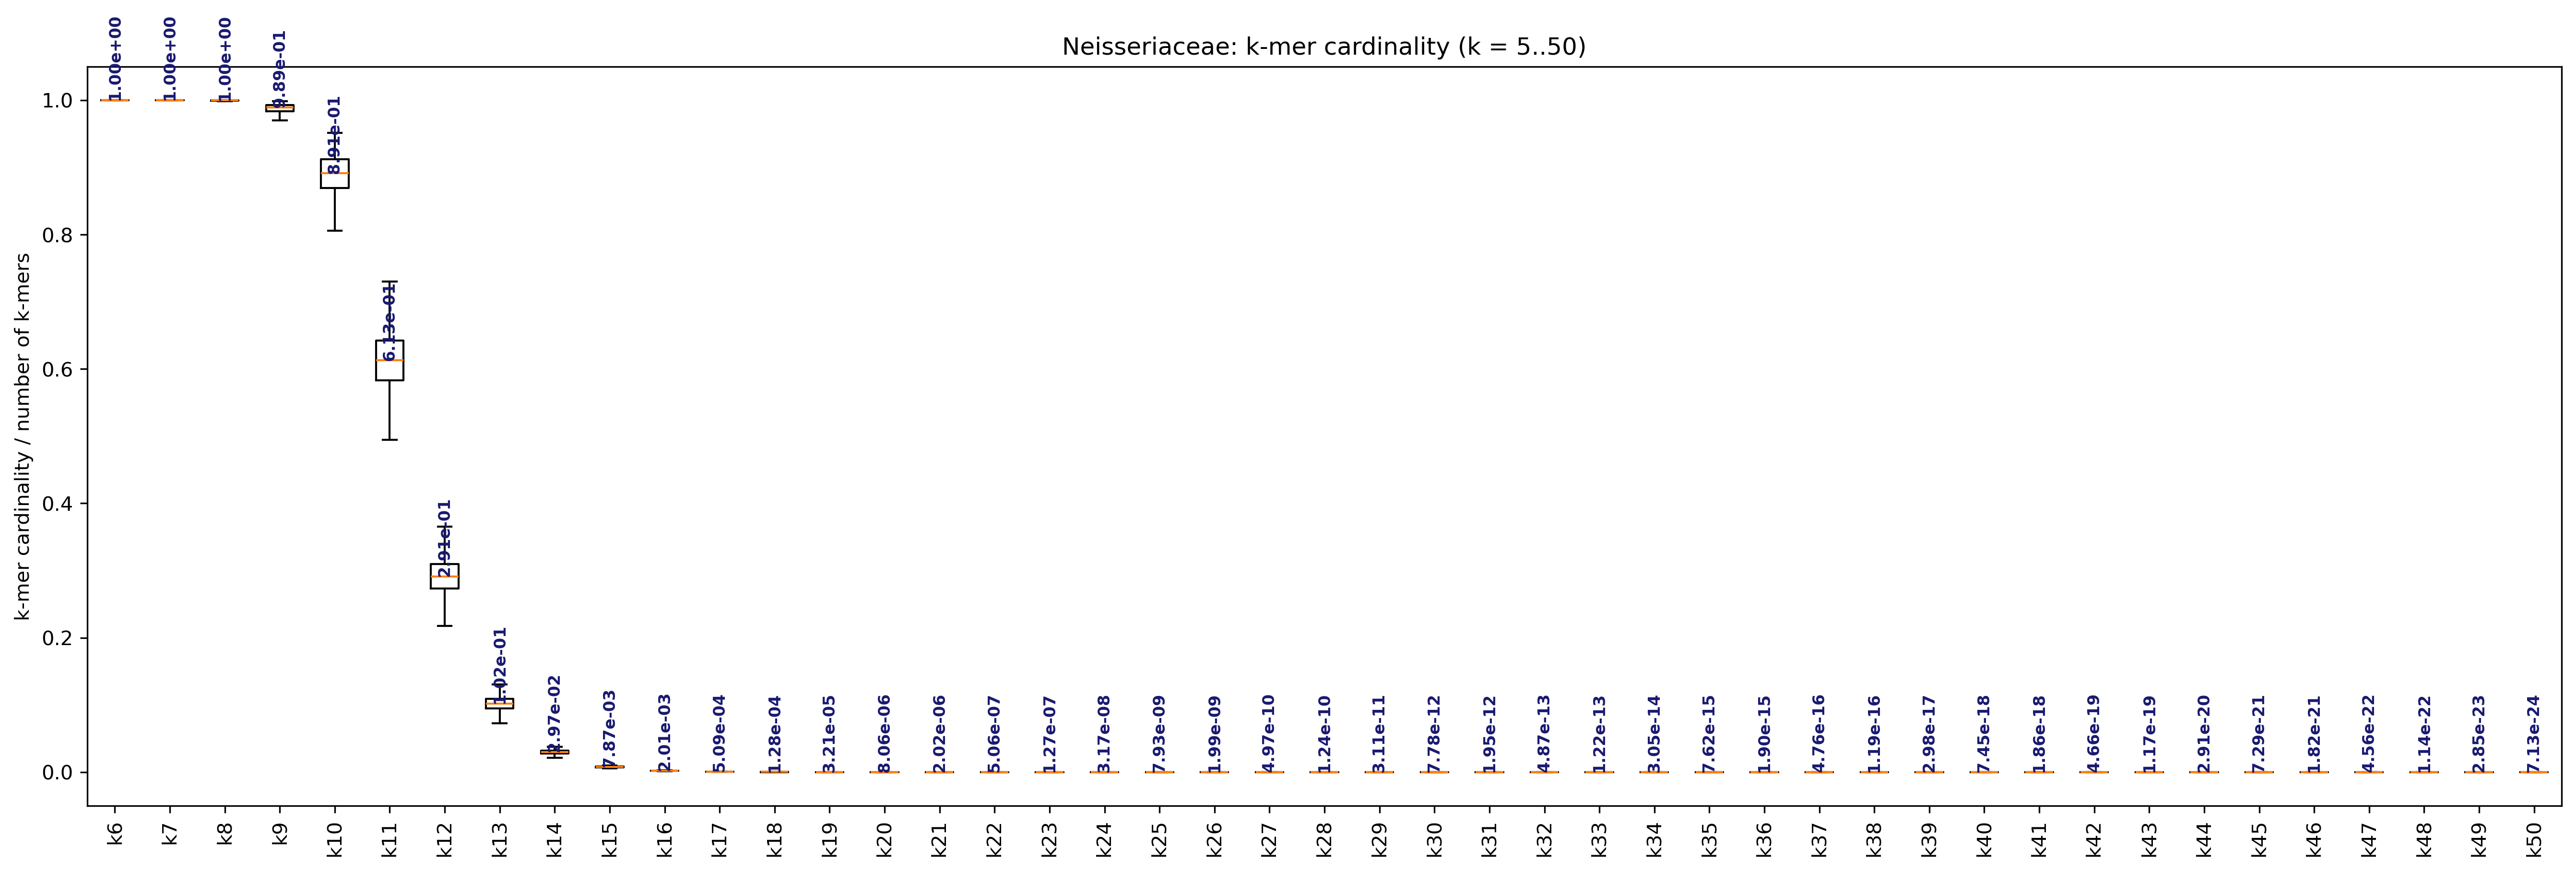

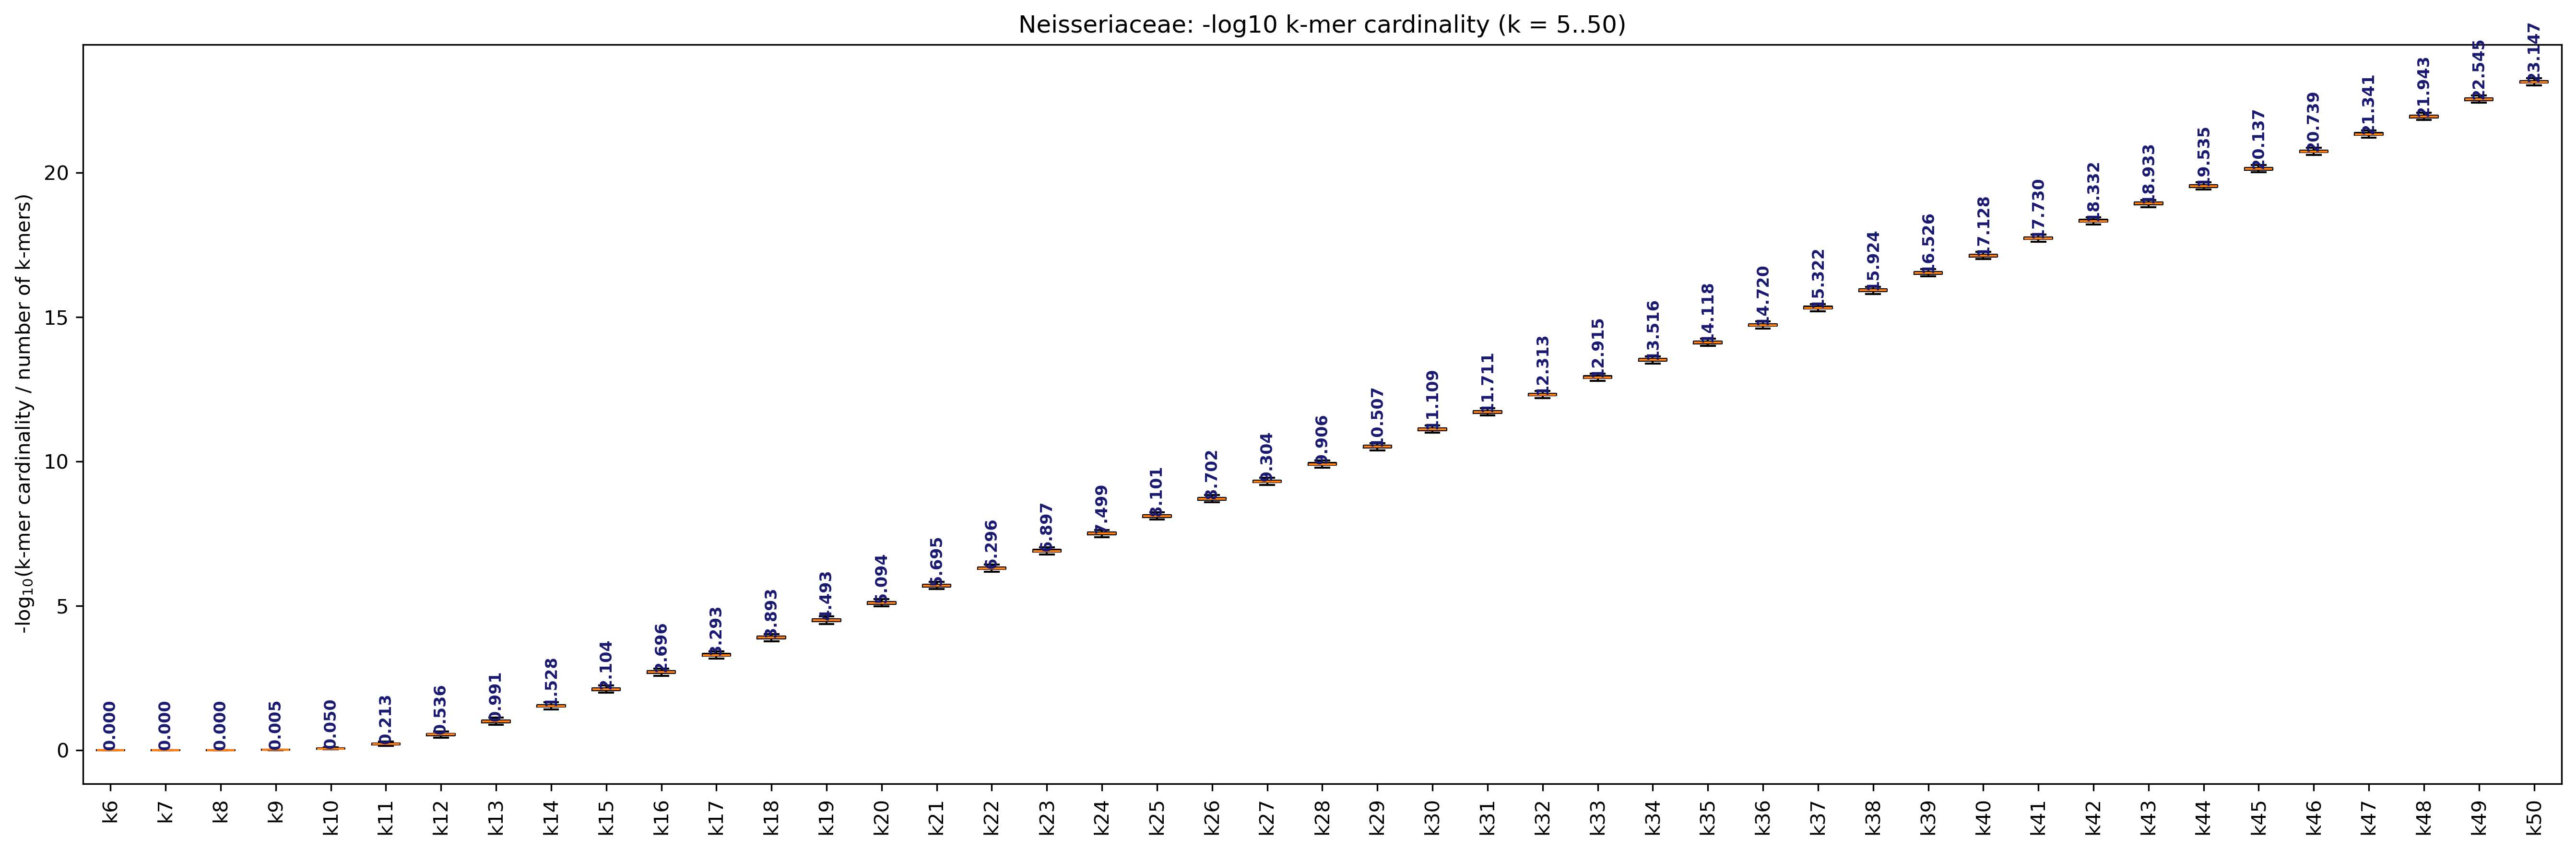

In [24]:
# plot k-mer cardinalities
k_min = 5
k_max = 50

for name, df in union_cardinality_datasets:
    print(f"Plotting k-mer cardinality for {name}")
    ok_k_mer.plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max)
    ok_k_mer.plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max, log=True)
    print()


# def plot_kmer_dashing_card(merged_card_df, name, k_min=5, k_max=64, log=False):


In [ ]:

# union_cardinality_datasets = [
#     ("Aquificota", aquificota_union_card_df),
#     ("Bacillales", bacillales_union_card_df),
#     ("Caldisericia", caldisericia_union_card_df),
#     ("Chlamydia", chlamydia_union_card_df),
#     ("Cyano", cyano_union_card_df),
#     ("Neisseriaceae", neisseriaceae_union_card_df),
# ]



In [25]:
# Compile k-mer cardinality stats per dataset.
# Each resulting DataFrame has k-mer lengths as columns and these rows:
#   1st quantile (25%), 2nd quantile (50%), 3rd quantile (75%), 4th quantile (100%),
#   average, standard deviation, variance.
k_min = 5
k_max = 50

dataset_kmer_stats = {}

for name, df in union_cardinality_datasets:
    cols = [f"k{k}_cardinality" for k in range(k_min, k_max + 1) if f"k{k}_cardinality" in df.columns]
    sub = df[cols].apply(pd.to_numeric, errors="coerce")

    stats_df = pd.DataFrame(
        {
            "1st quantile":       sub.quantile(0.25),
            "2nd quantile":       sub.quantile(0.50),
            "3rd quantile":       sub.quantile(0.75),
            "4th quantile":       sub.quantile(1.00),
            "average":            sub.mean(),
            "standard deviation": sub.std(),
            "variance":           sub.var(),
        }
    ).T
    stats_df.columns = [int(c[1:].split("_")[0]) for c in cols]
    stats_df.columns.name = "k"

    dataset_kmer_stats[name] = stats_df
    print(name)
    print(stats_df)
    print()



Aquificota
k                             6         7         8         9         10  \
1st quantile        1.000000e+00  0.999390  0.988874  0.934921  0.761698   
2nd quantile        1.000000e+00  0.999878  0.993677  0.953552  0.799504   
3rd quantile        1.000000e+00  1.000000  0.996717  0.966539  0.829730   
4th quantile        1.000000e+00  1.000000  0.999909  0.993080  0.903356   
average             9.999705e-01  0.999459  0.991487  0.947529  0.791236   
standard deviation  1.392760e-04  0.001121  0.007751  0.027829  0.053448   
variance            1.939779e-08  0.000001  0.000060  0.000774  0.002857   

k                         11        12        13        14            15  ...  \
1st quantile        0.464185  0.201401  0.066746  0.018856  4.933746e-03  ...   
2nd quantile        0.498972  0.218542  0.072613  0.020553  5.394099e-03  ...   
3rd quantile        0.528787  0.233480  0.078111  0.022193  5.835299e-03  ...   
4th quantile        0.617318  0.289887  0.101980  0.0297

Cyano
k                             6             7             8         9   \
1st quantile        1.000000e+00  1.000000e+00  9.990880e-01  0.992905   
2nd quantile        1.000000e+00  1.000000e+00  9.996656e-01  0.995987   
3rd quantile        1.000000e+00  1.000000e+00  9.999088e-01  0.998016   
4th quantile        1.000000e+00  1.000000e+00  1.000000e+00  1.000000   
average             9.999996e-01  9.999857e-01  9.993279e-01  0.994925   
standard deviation  1.385582e-05  6.406196e-05  9.177316e-04  0.004142   
variance            1.919837e-10  4.103934e-09  8.422312e-07  0.000017   

k                         10        11        12        13        14  \
1st quantile        0.967372  0.851402  0.536580  0.222250  0.068900   
2nd quantile        0.975728  0.879136  0.582018  0.250927  0.079559   
3rd quantile        0.982720  0.899953  0.620593  0.277625  0.089802   
4th quantile        0.999070  0.963377  0.765577  0.402236  0.147959   
average             0.973679  0.871345  0

In [26]:
dataset_kmer_stats.keys()


dict_keys(['Aquificota', 'Bacillales', 'Caldisericia', 'Chlamydia', 'Cyano', 'Neisseriaceae'])

In [18]:
# Save each DataFrame in dataset_kmer_stats as a TSV file
# for name, stats_df in dataset_kmer_stats.items():
    # stats_df.to_csv(f"{name}_kmer_stats.tsv", sep="\t")

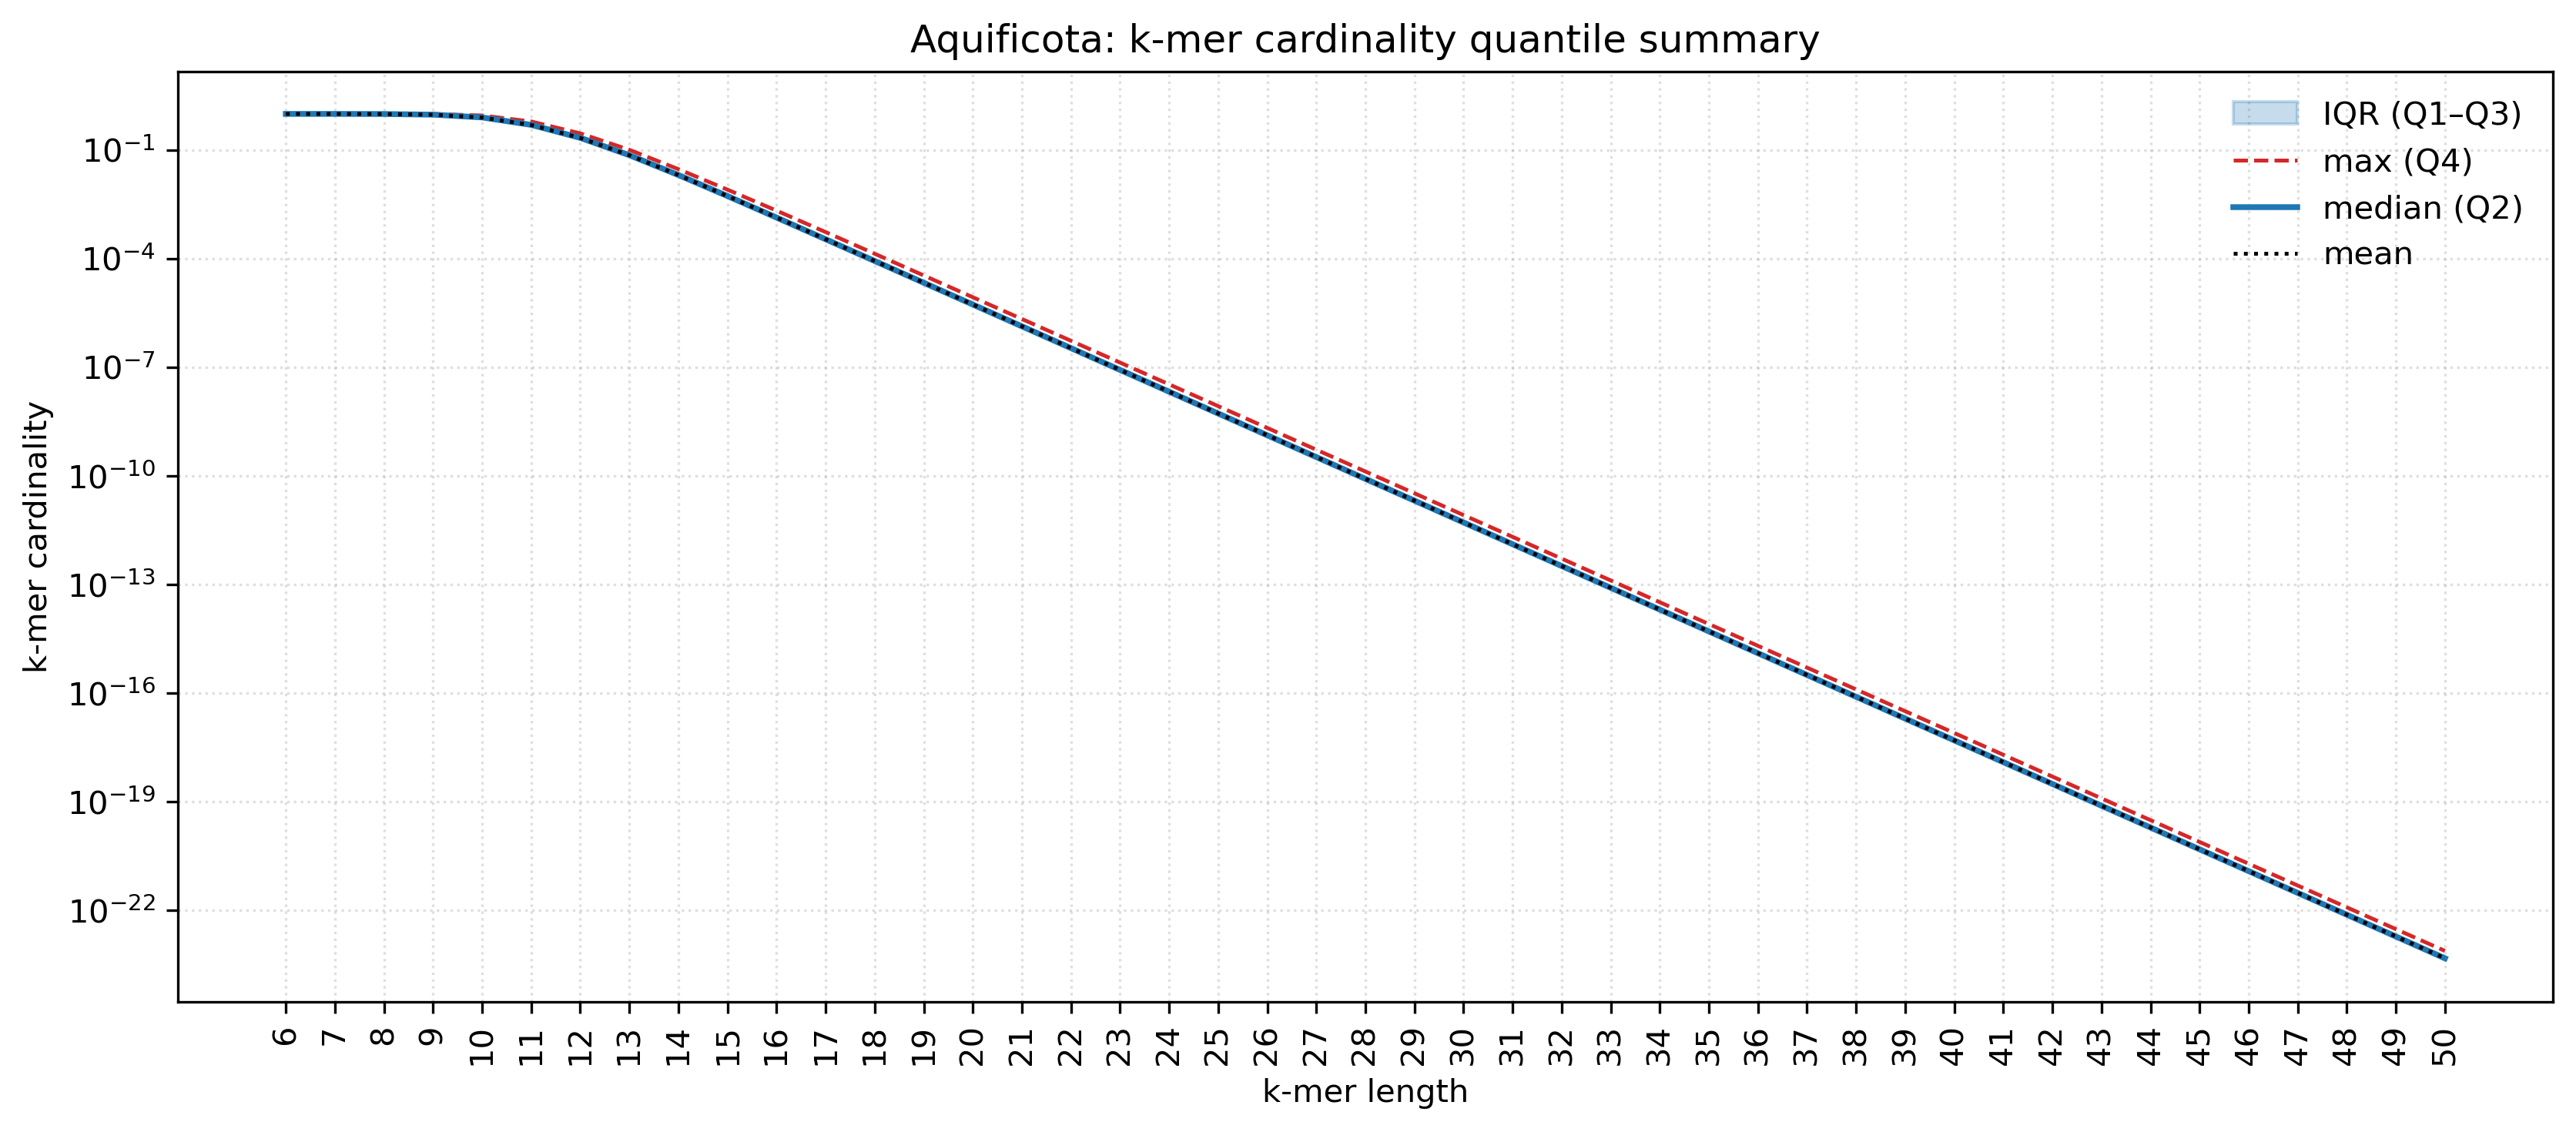

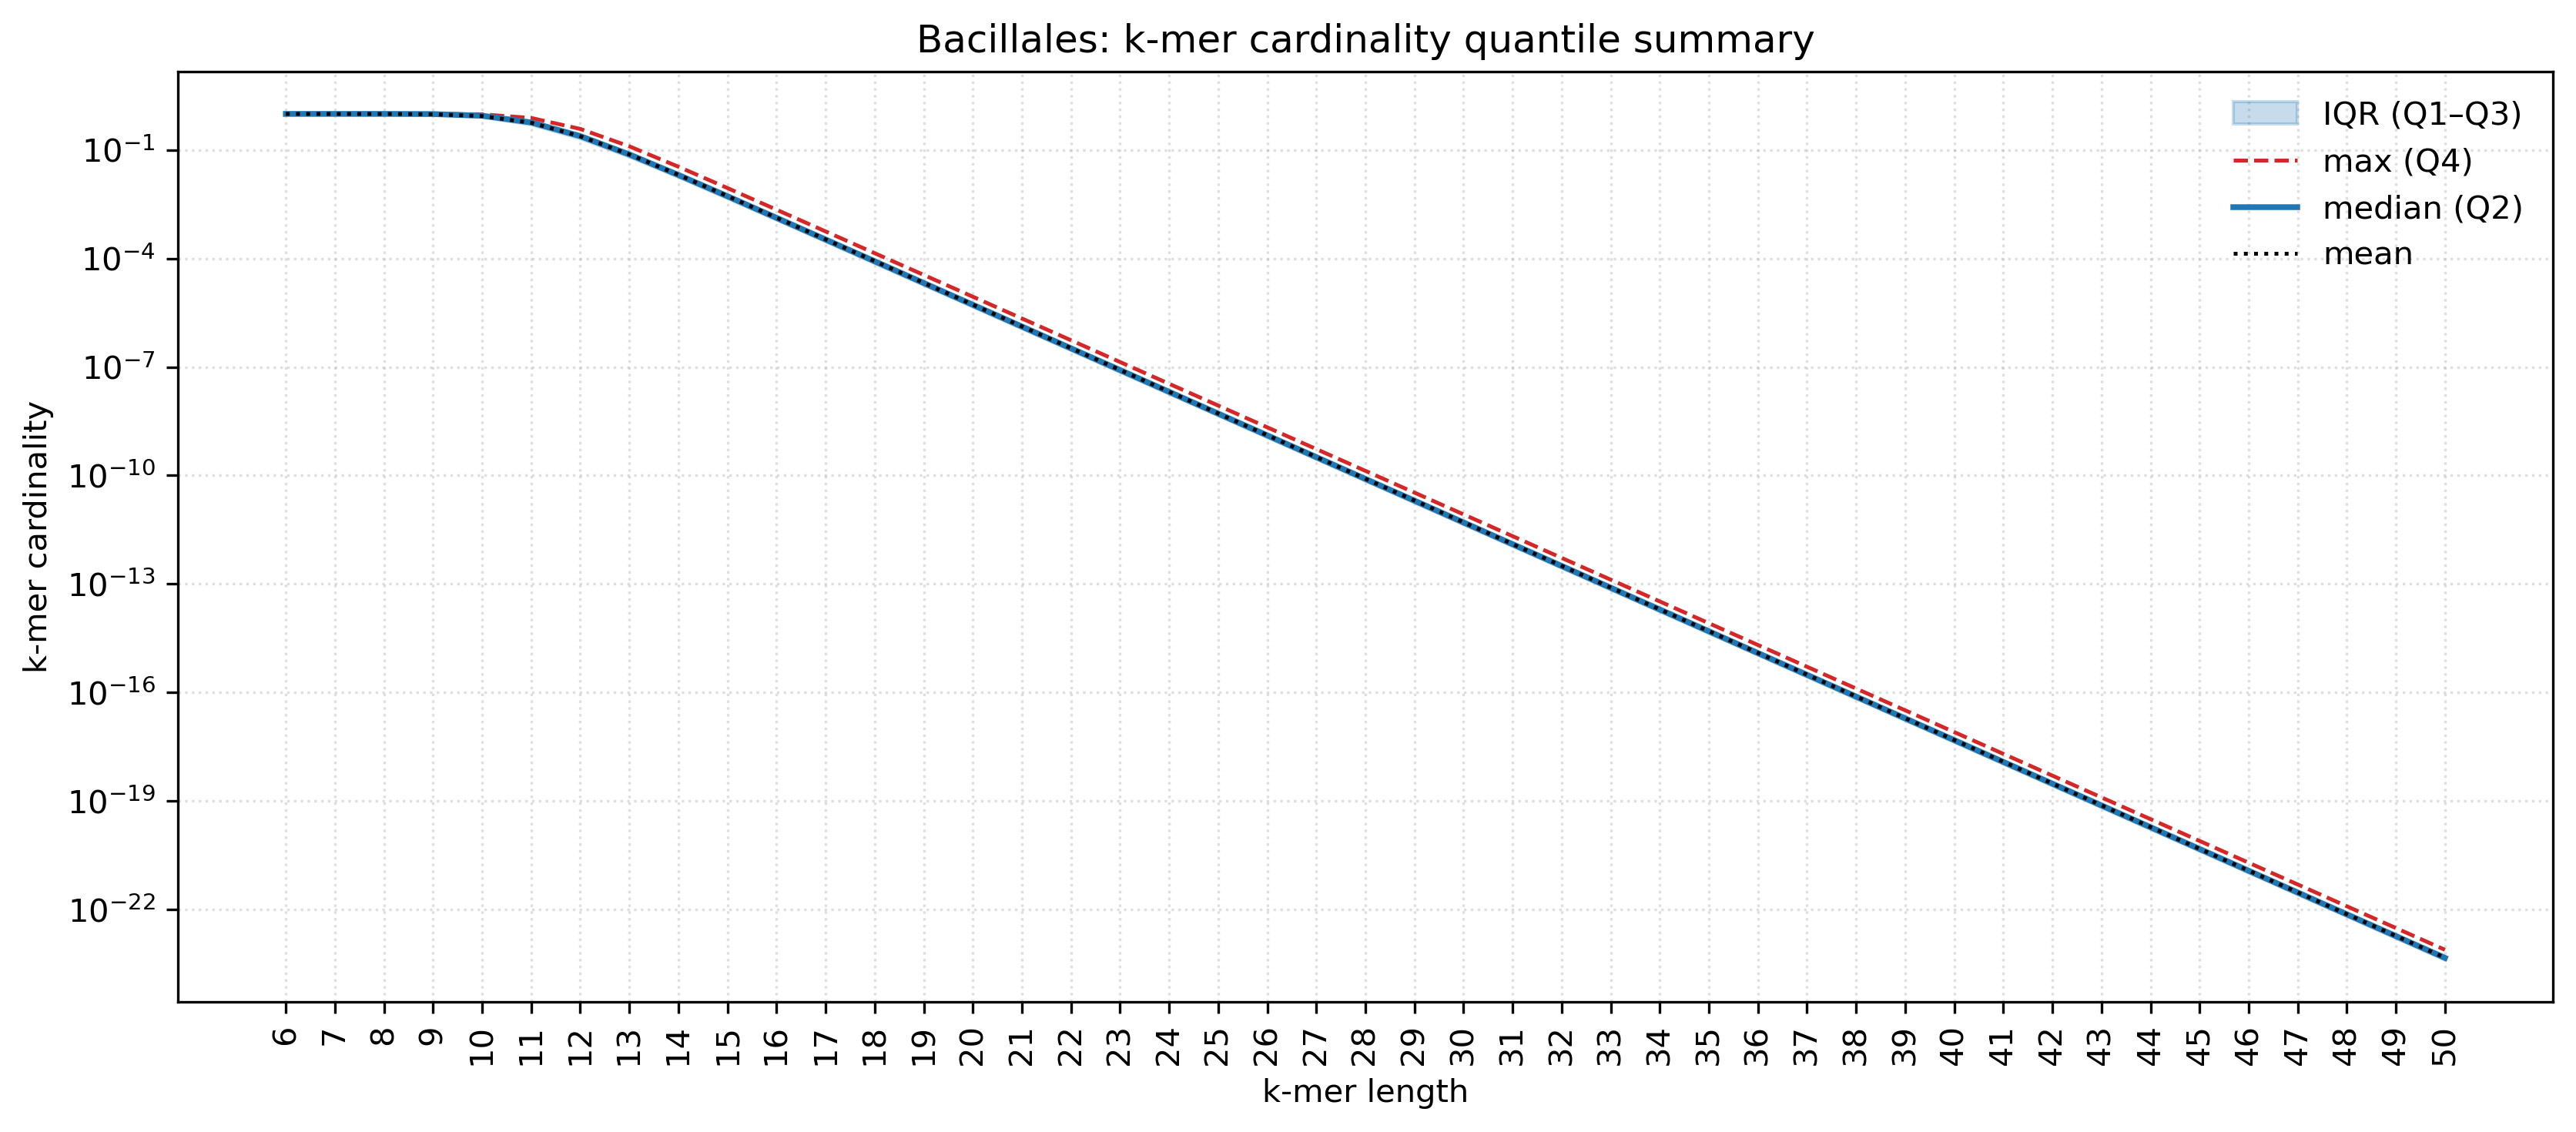

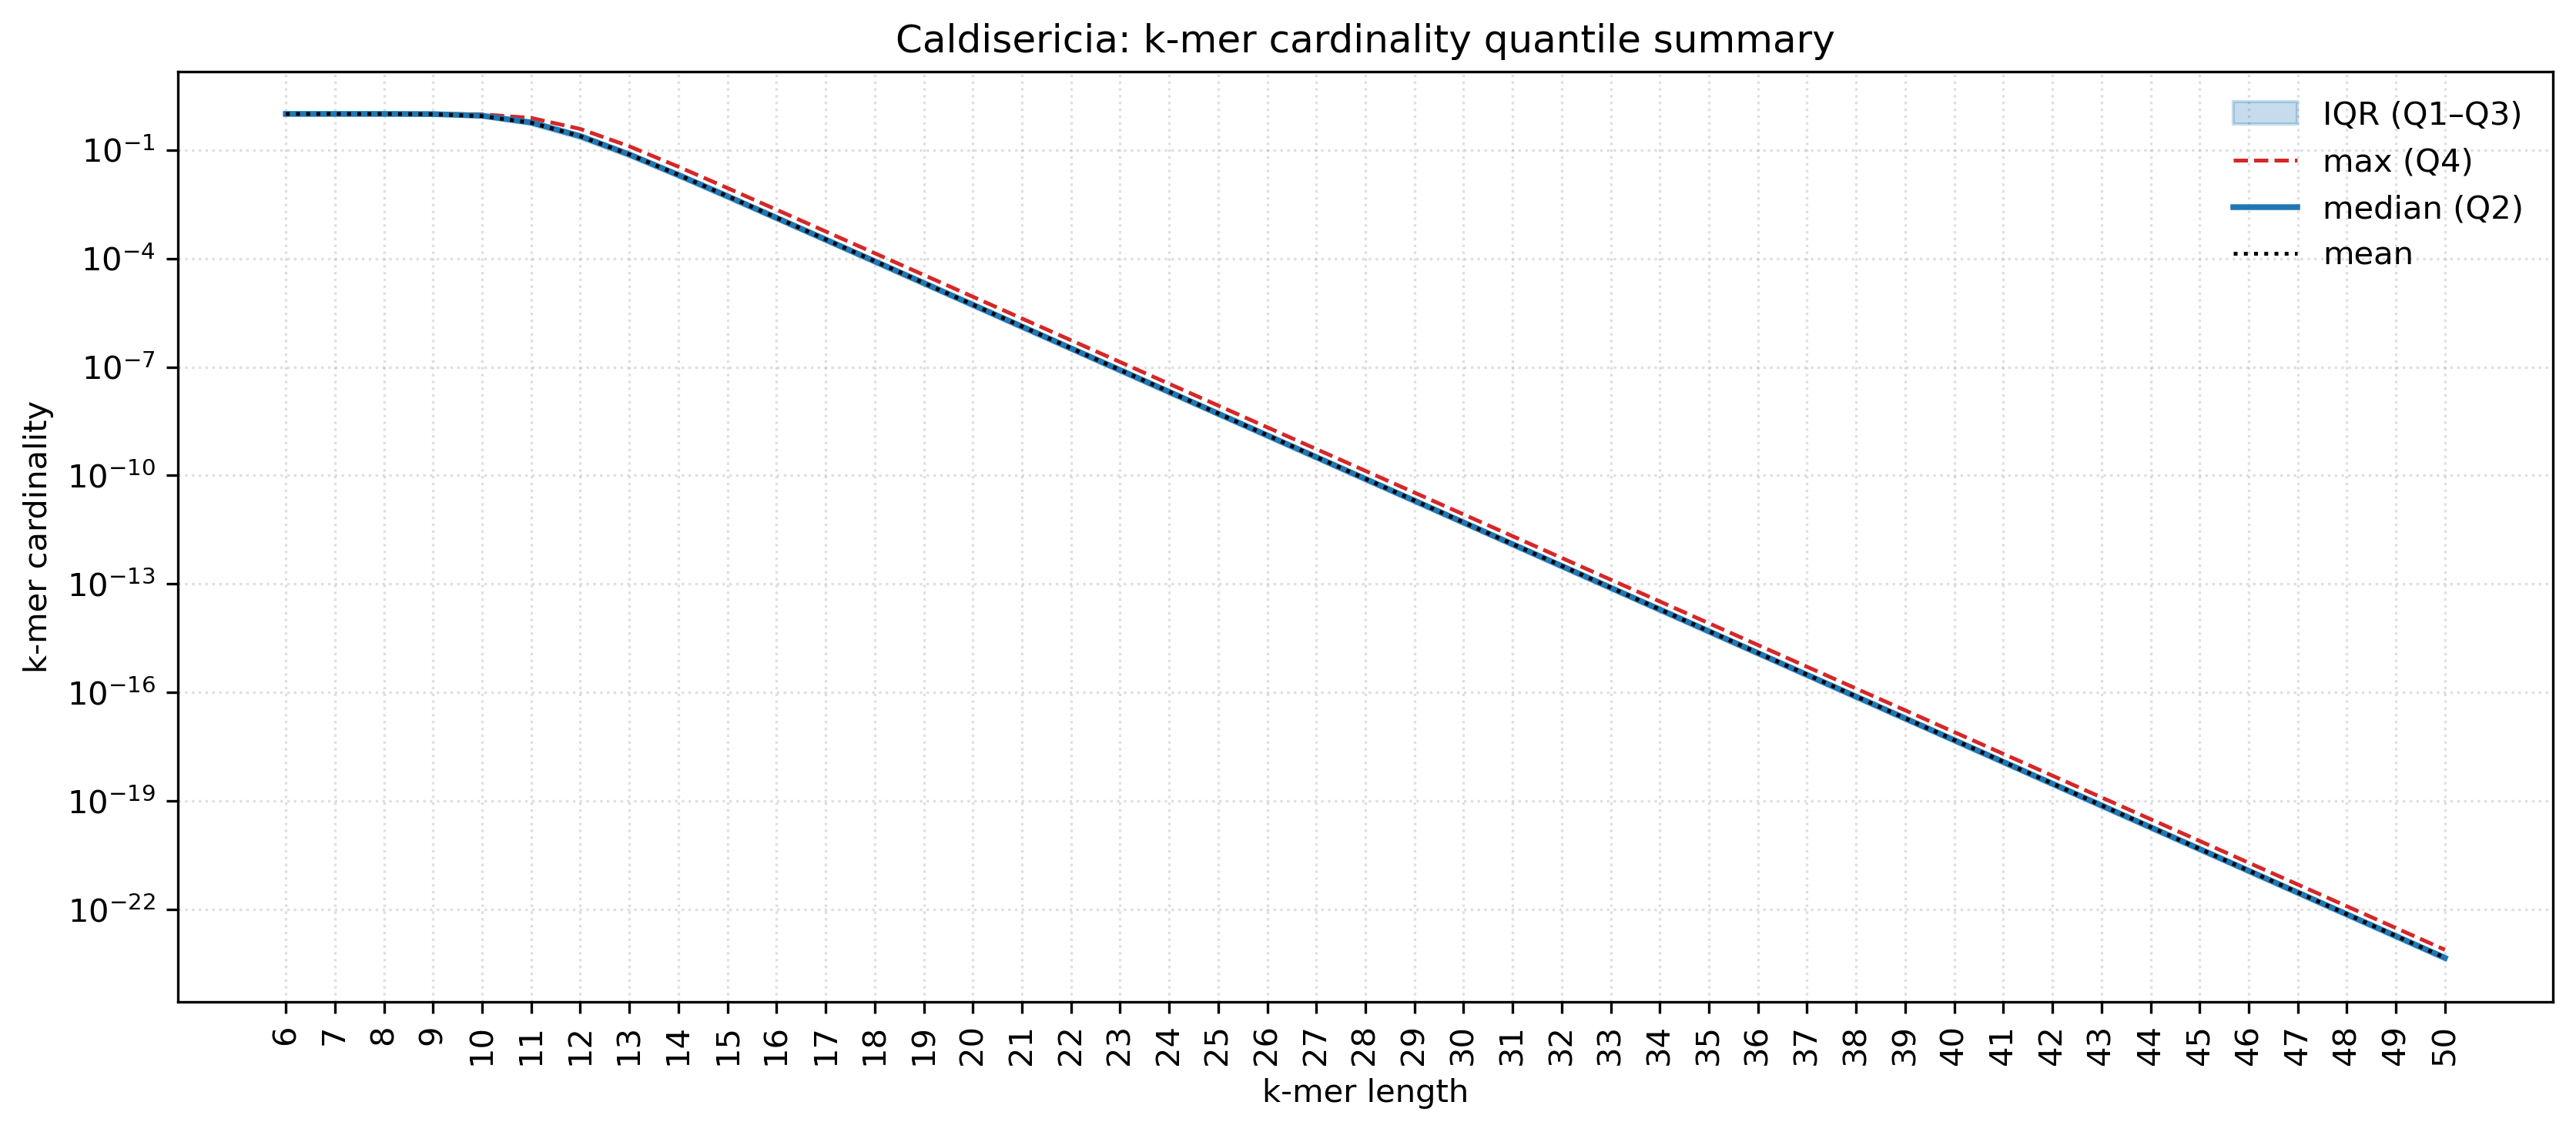

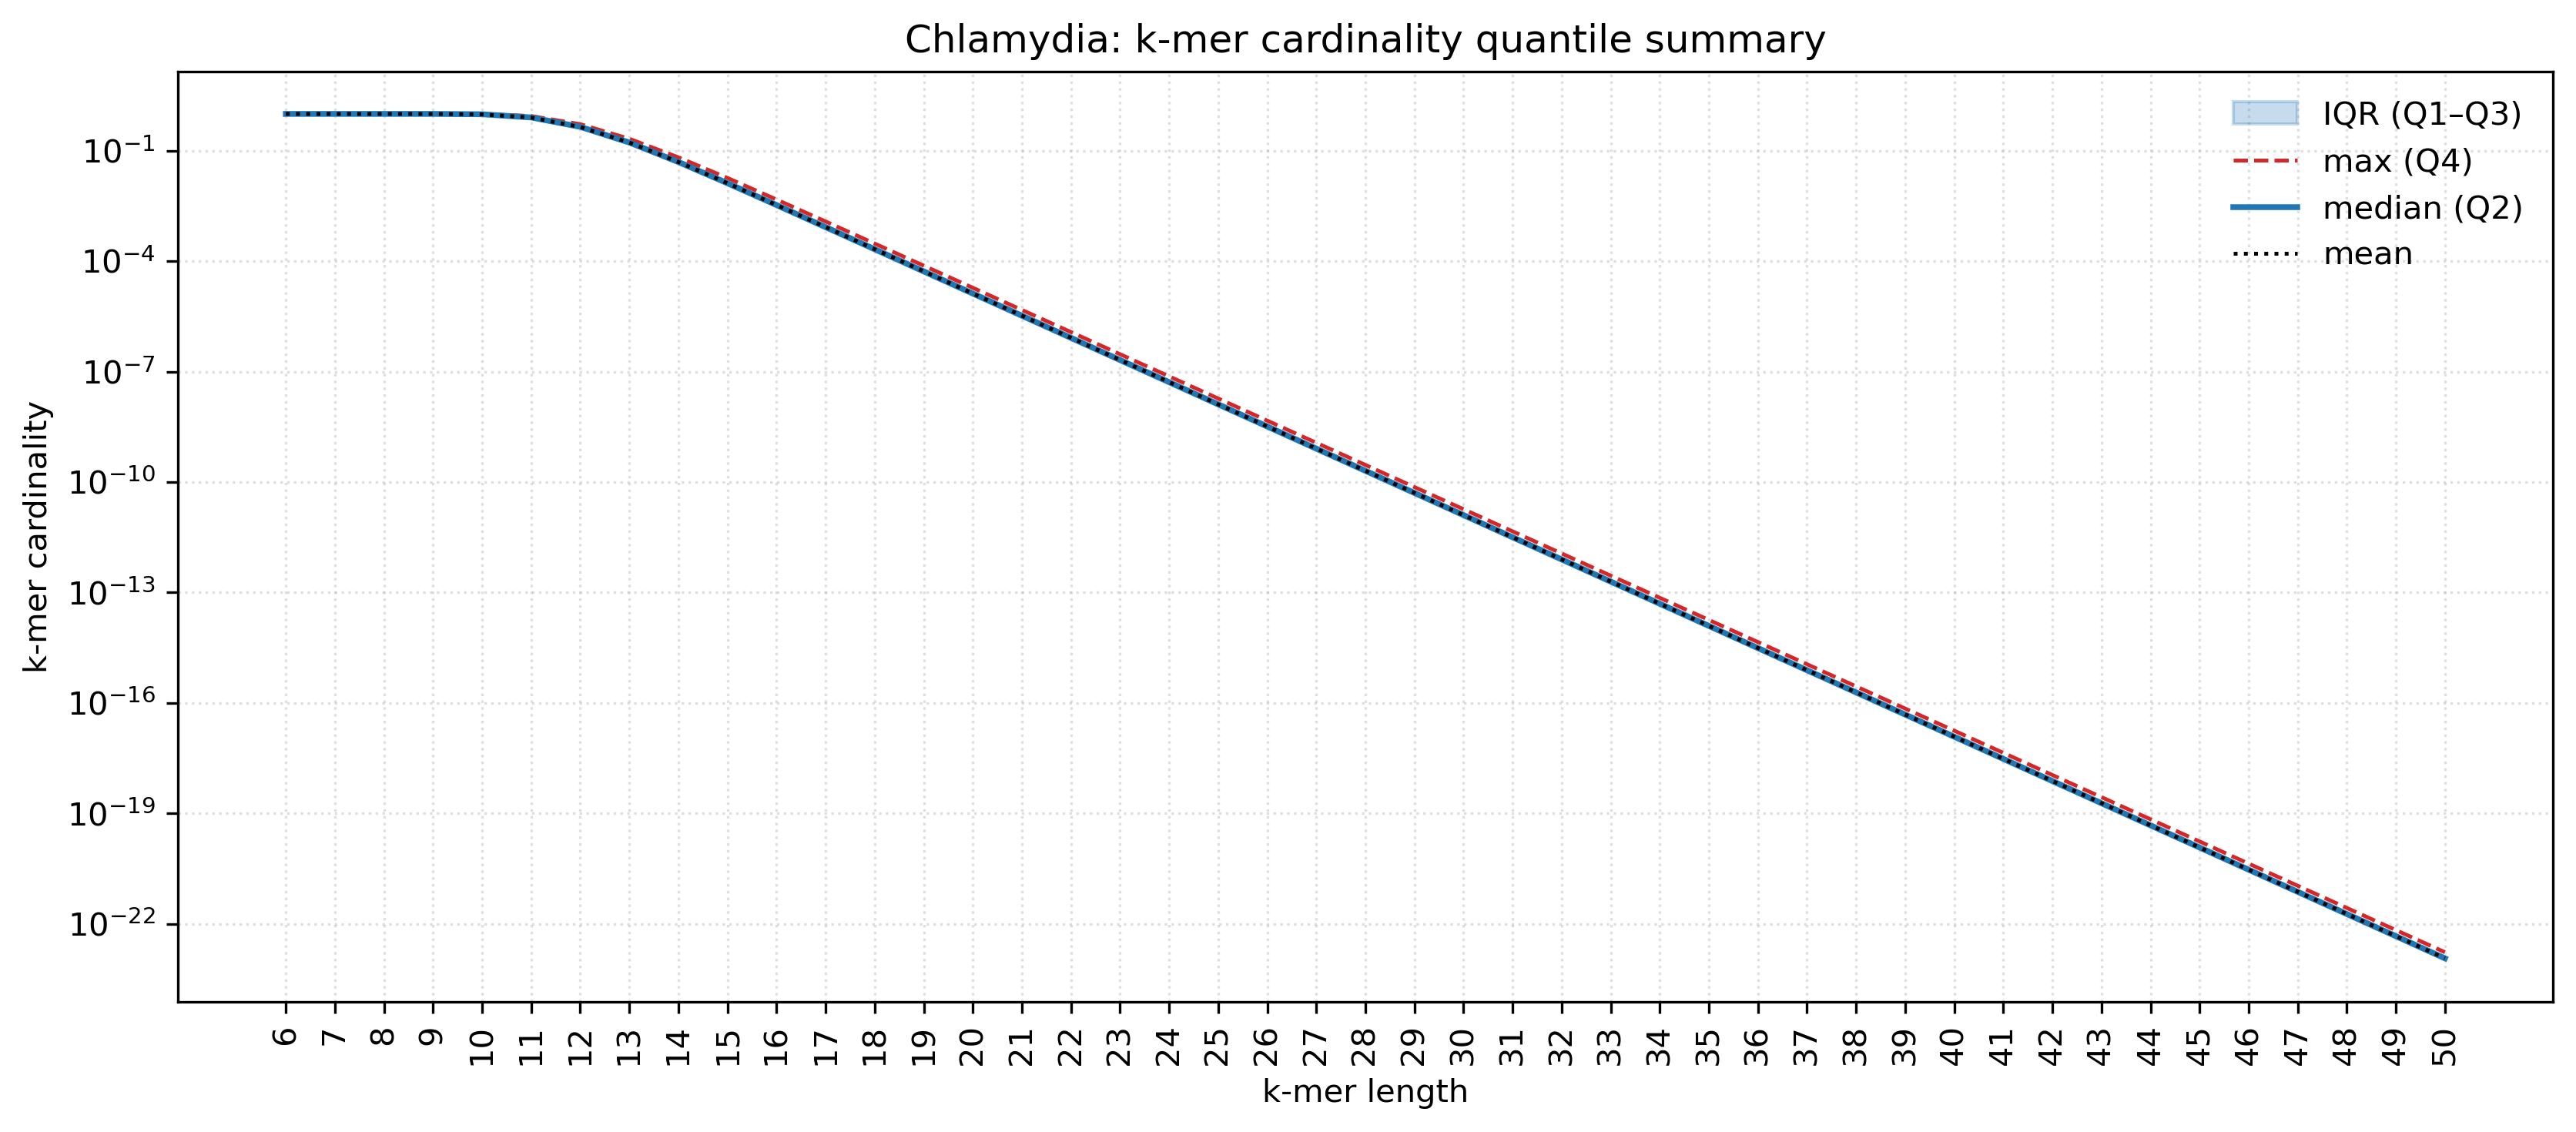

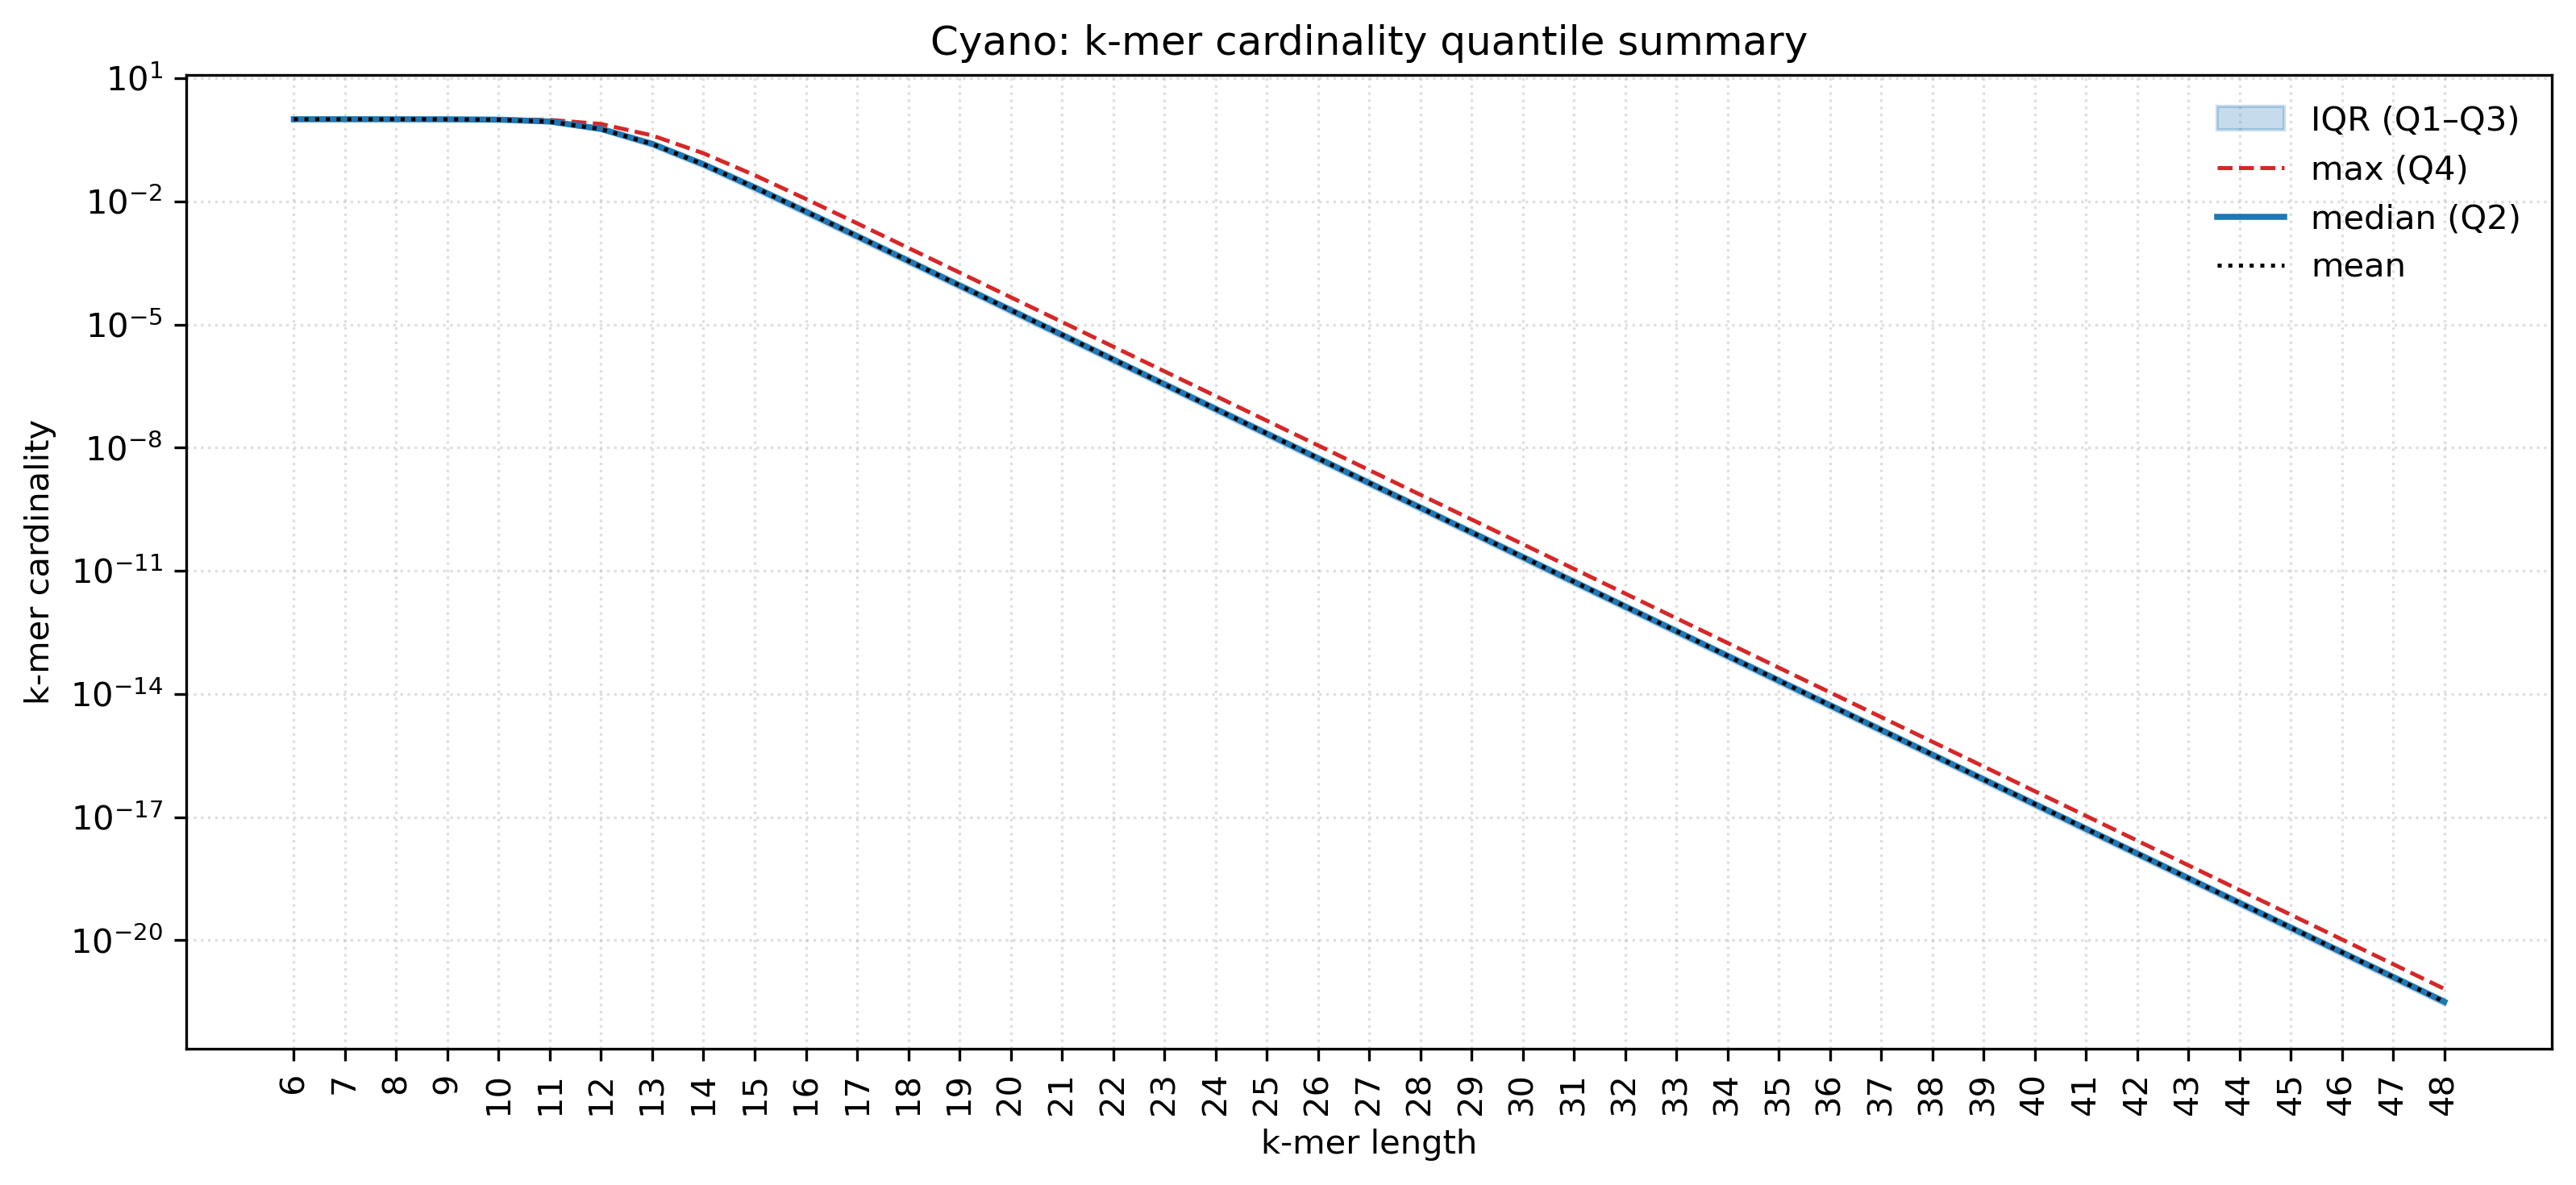

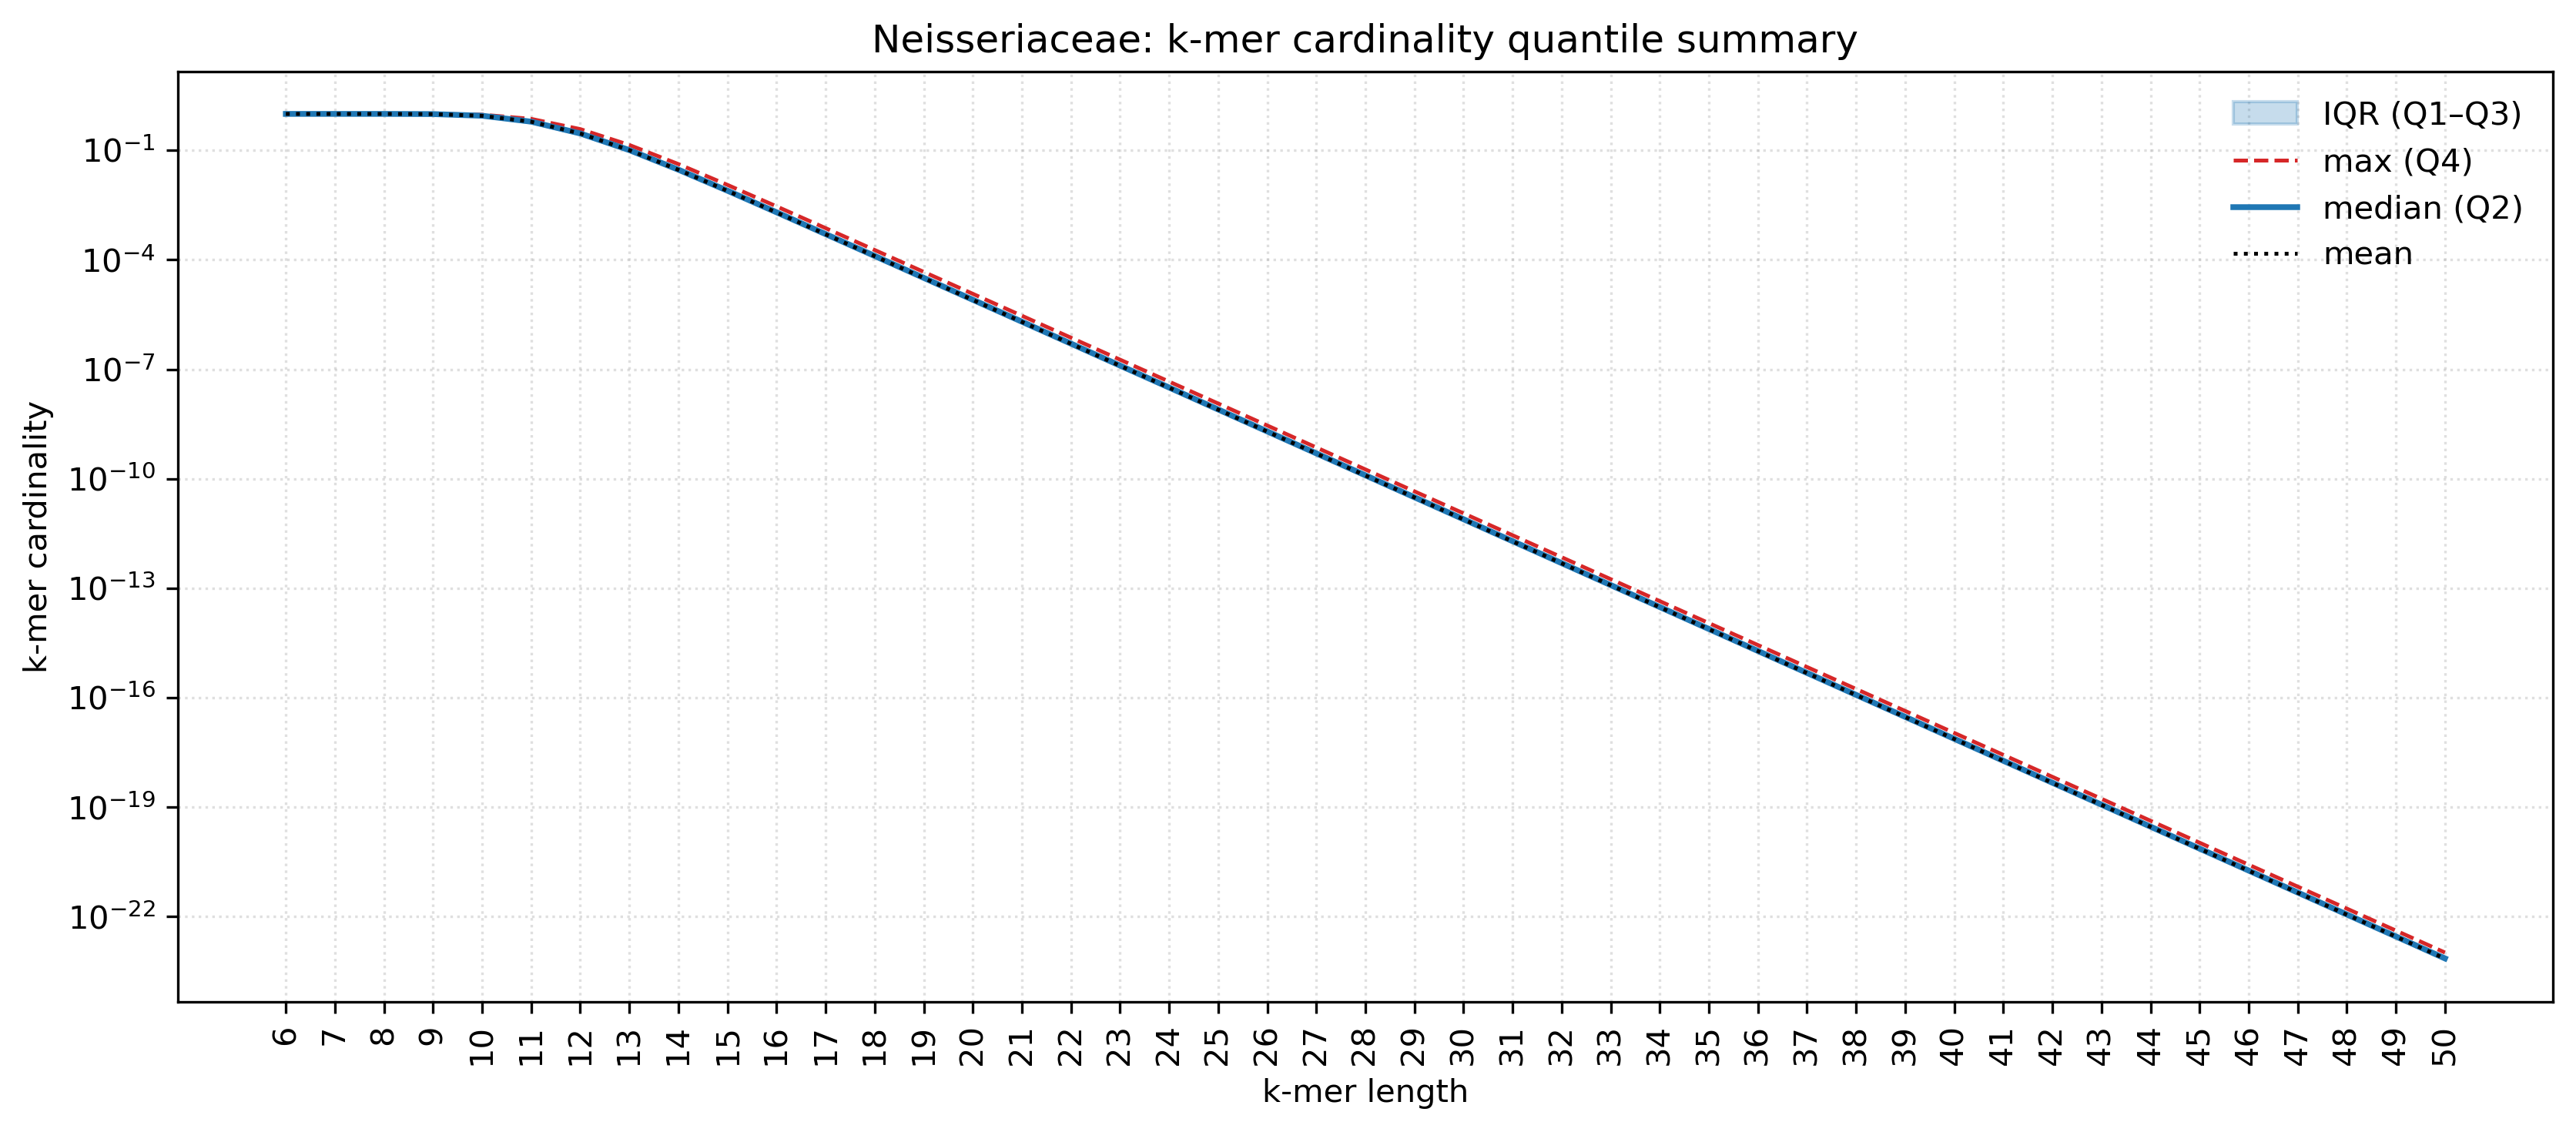

In [27]:
# Plot a quantile summary per dataset.
# x-axis: k-mer length (columns of stats_df)
# y-axis: k-mer cardinality (log scale, since values span many orders of magnitude)
# Shaded band: inter-quartile range (Q1 -> Q3)
# Lines: Q2 (median), Q4 (max), and the mean

for name, stats_df in dataset_kmer_stats.items():
    ks = np.asarray(stats_df.columns, dtype=int)
    q1 = stats_df.loc["1st quantile"].to_numpy(dtype=float)
    q2 = stats_df.loc["2nd quantile"].to_numpy(dtype=float)
    q3 = stats_df.loc["3rd quantile"].to_numpy(dtype=float)
    q4 = stats_df.loc["4th quantile"].to_numpy(dtype=float)
    mean = stats_df.loc["average"].to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(max(8, len(ks) * 0.25), 5))

    ax.fill_between(ks, q1, q3, alpha=0.25, color="C0", label="IQR (Q1\u2013Q3)")
    ax.plot(ks, q4, color="C3", linestyle="--", linewidth=1.2, label="max (Q4)")
    ax.plot(ks, q2, color="C0", linewidth=1.8, label="median (Q2)")
    ax.plot(ks, mean, color="k", linestyle=":", linewidth=1.2, label="mean")

    ax.set_yscale("log")
    ax.set_xlabel("k-mer length")
    ax.set_ylabel("k-mer cardinality")
    ax.set_title(f"{name}: k-mer cardinality quantile summary")
    ax.set_xticks(ks)
    ax.tick_params(axis="x", rotation=90)
    ax.grid(True, which="both", linestyle=":", alpha=0.4)
    ax.legend(loc="best", frameon=False)

    plt.tight_layout()
    plt.show()


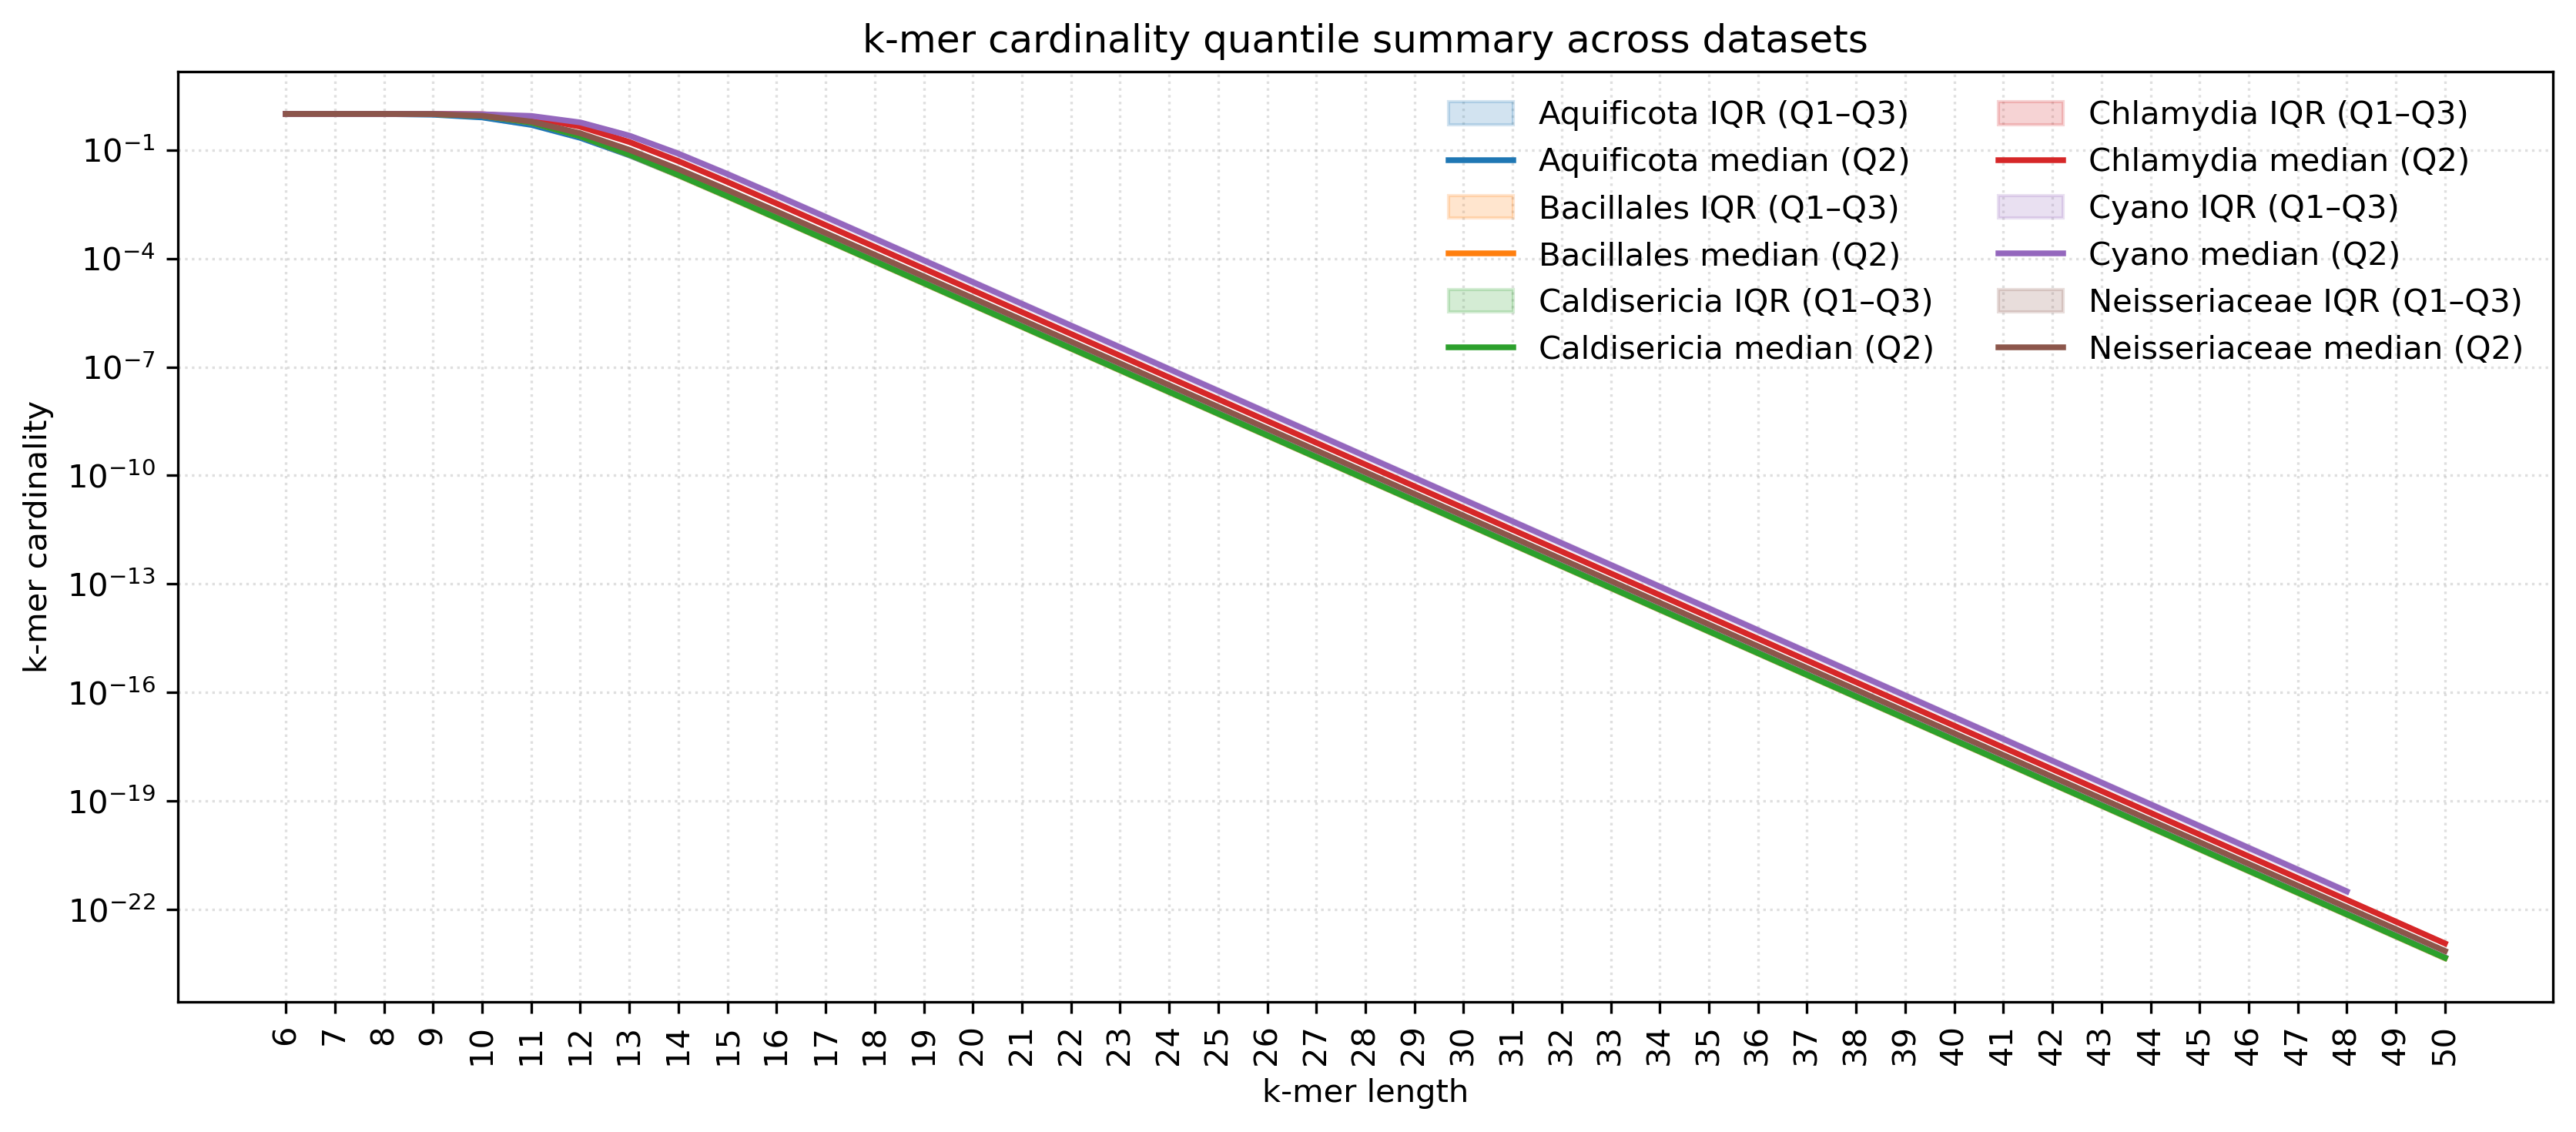

In [28]:

# Plot a quantile summary for all datasets in the same plot.
# x-axis: k-mer length (columns of stats_df)
# y-axis: k-mer cardinality (log scale, since values span many orders of magnitude)
# For each dataset: shaded band = IQR (Q1–Q3), line = median; all use different colors

fig, ax = plt.subplots(figsize=(max(8, max(len(df.columns) for df in dataset_kmer_stats.values()) * 0.25), 5))
colors = plt.cm.get_cmap("tab10")
for idx, (name, stats_df) in enumerate(dataset_kmer_stats.items()):
    color = colors(idx % 10)
    ks = np.asarray(stats_df.columns, dtype=int)
    q1 = stats_df.loc["1st quantile"].to_numpy(dtype=float)
    q2 = stats_df.loc["2nd quantile"].to_numpy(dtype=float)
    q3 = stats_df.loc["3rd quantile"].to_numpy(dtype=float)
    ax.fill_between(ks, q1, q3, alpha=0.2, color=color, label=f"{name} IQR (Q1–Q3)")
    ax.plot(ks, q2, color=color, linewidth=1.8, label=f"{name} median (Q2)")

ax.set_yscale("log")
ax.set_xlabel("k-mer length")
ax.set_ylabel("k-mer cardinality")
ax.set_title("k-mer cardinality quantile summary across datasets")
all_ks = np.unique(np.concatenate([np.asarray(df.columns, dtype=int) for df in dataset_kmer_stats.values()]))
ax.set_xticks(all_ks)
ax.tick_params(axis="x", rotation=90)
ax.grid(True, which="both", linestyle=":", alpha=0.4)
ax.legend(loc="best", frameon=False, ncol=2)
plt.tight_layout()
plt.show()


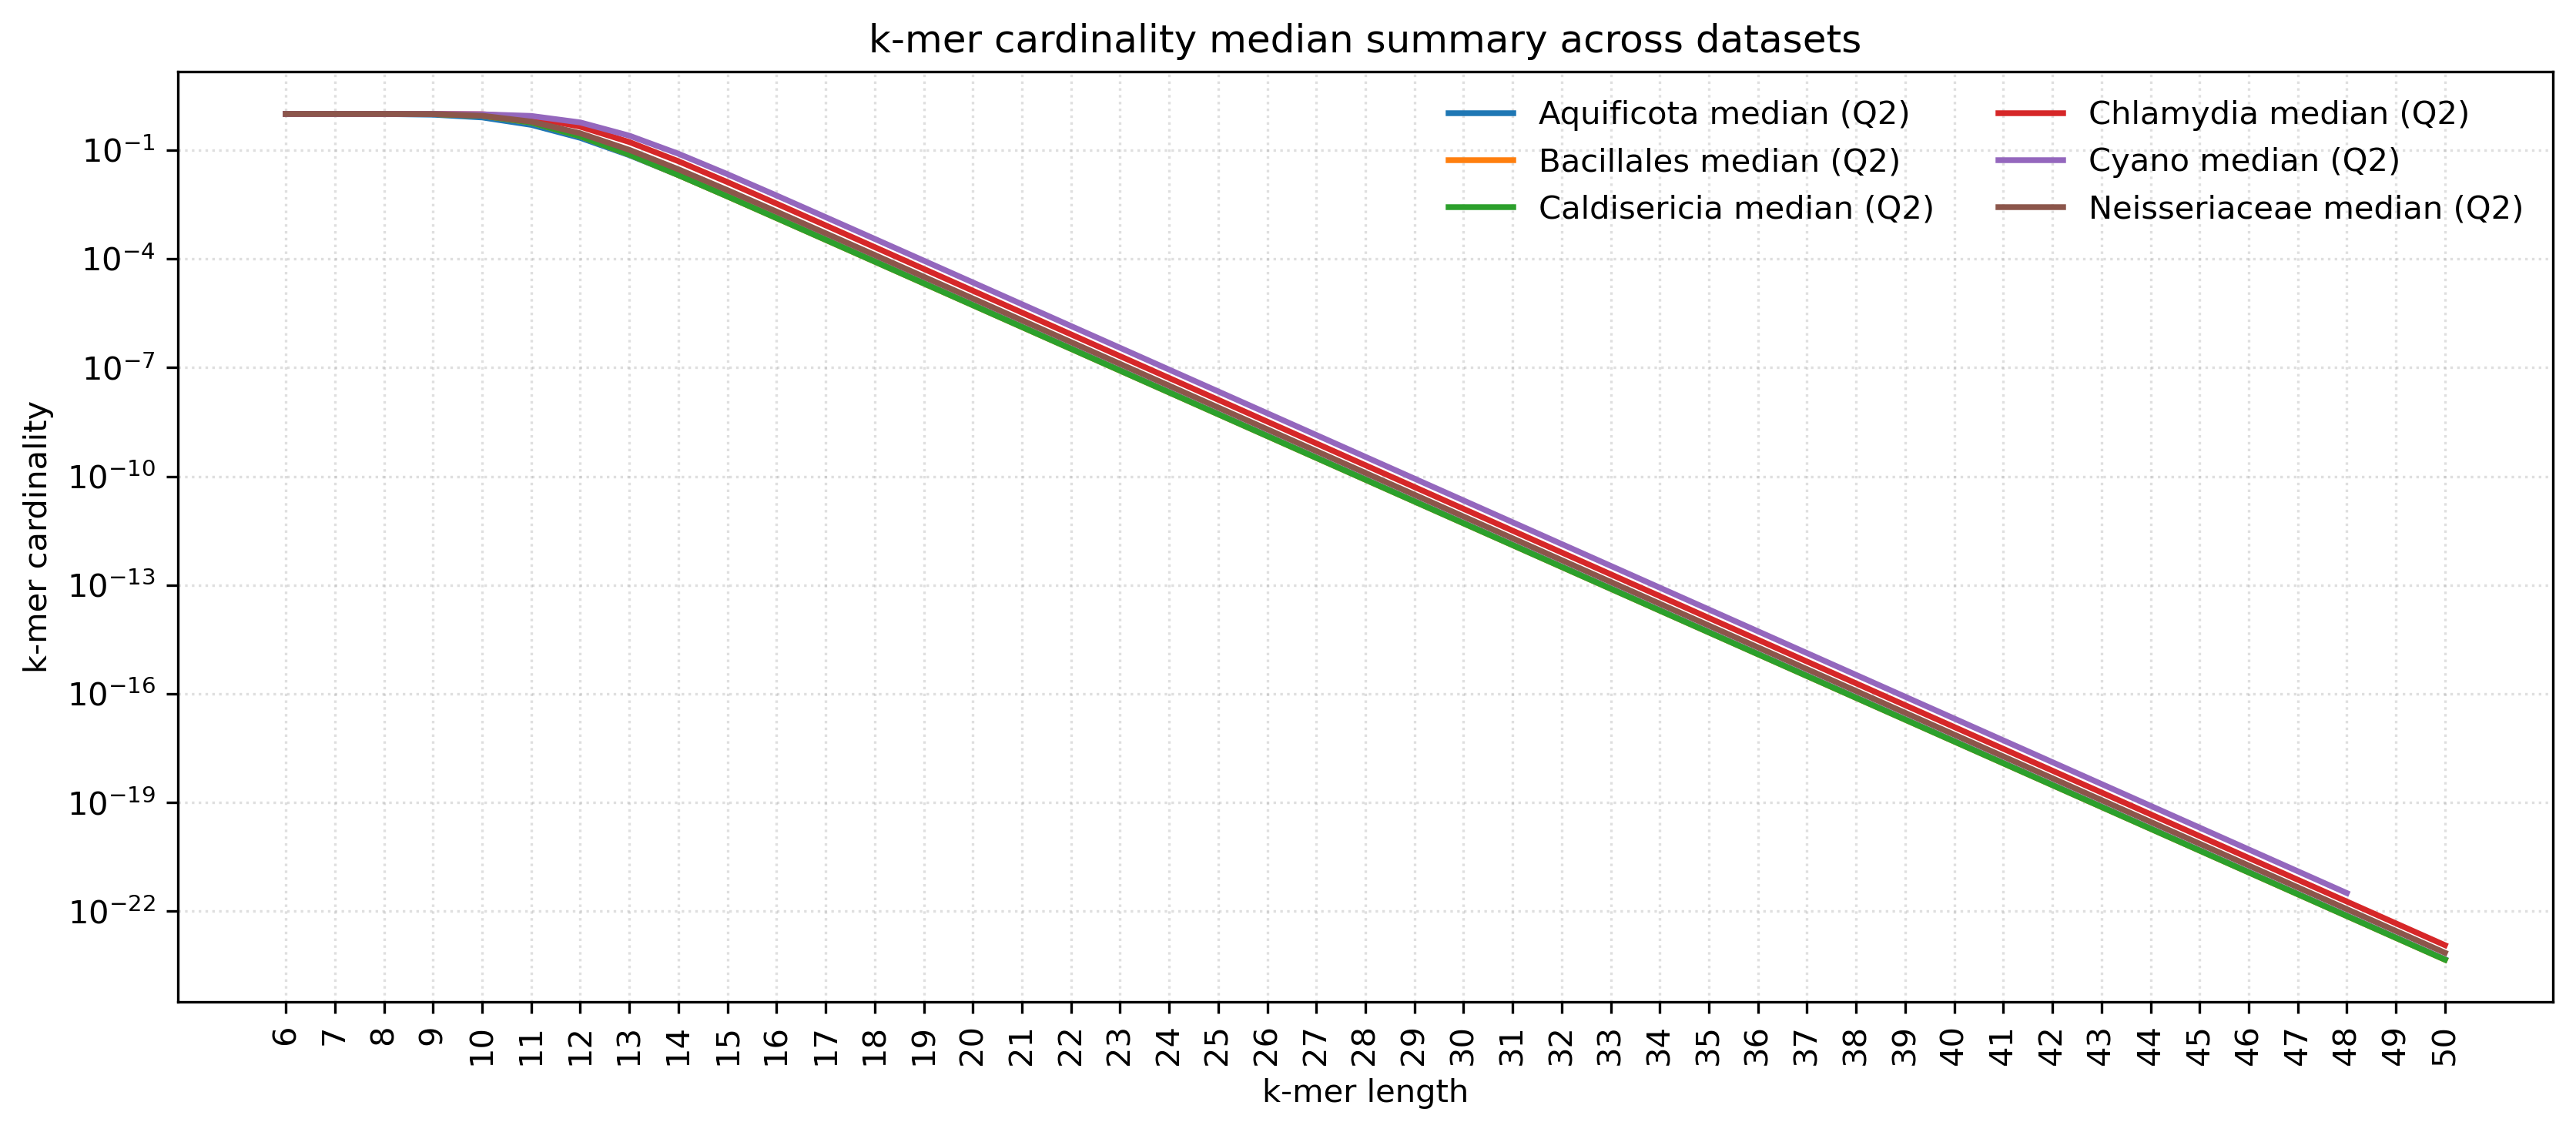

In [29]:
# Plot only the median for all datasets in the same plot.
# x-axis: k-mer length (columns of stats_df)
# y-axis: k-mer cardinality (log scale, since values span many orders of magnitude)

fig, ax = plt.subplots(figsize=(max(8, max(len(df.columns) for df in dataset_kmer_stats.values()) * 0.25), 5))
colors = plt.cm.get_cmap("tab10")
for idx, (name, stats_df) in enumerate(dataset_kmer_stats.items()):
    color = colors(idx % 10)
    ks = np.asarray(stats_df.columns, dtype=int)
    q2 = stats_df.loc["2nd quantile"].to_numpy(dtype=float)
    ax.plot(ks, q2, color=color, linewidth=1.8, label=f"{name} median (Q2)")

ax.set_yscale("log")
ax.set_xlabel("k-mer length")
ax.set_ylabel("k-mer cardinality")
ax.set_title("k-mer cardinality median summary across datasets")
all_ks = np.unique(np.concatenate([np.asarray(df.columns, dtype=int) for df in dataset_kmer_stats.values()]))
ax.set_xticks(all_ks)
ax.tick_params(axis="x", rotation=90)
ax.grid(True, which="both", linestyle=":", alpha=0.4)
ax.legend(loc="best", frameon=False, ncol=2)
plt.tight_layout()
plt.show()


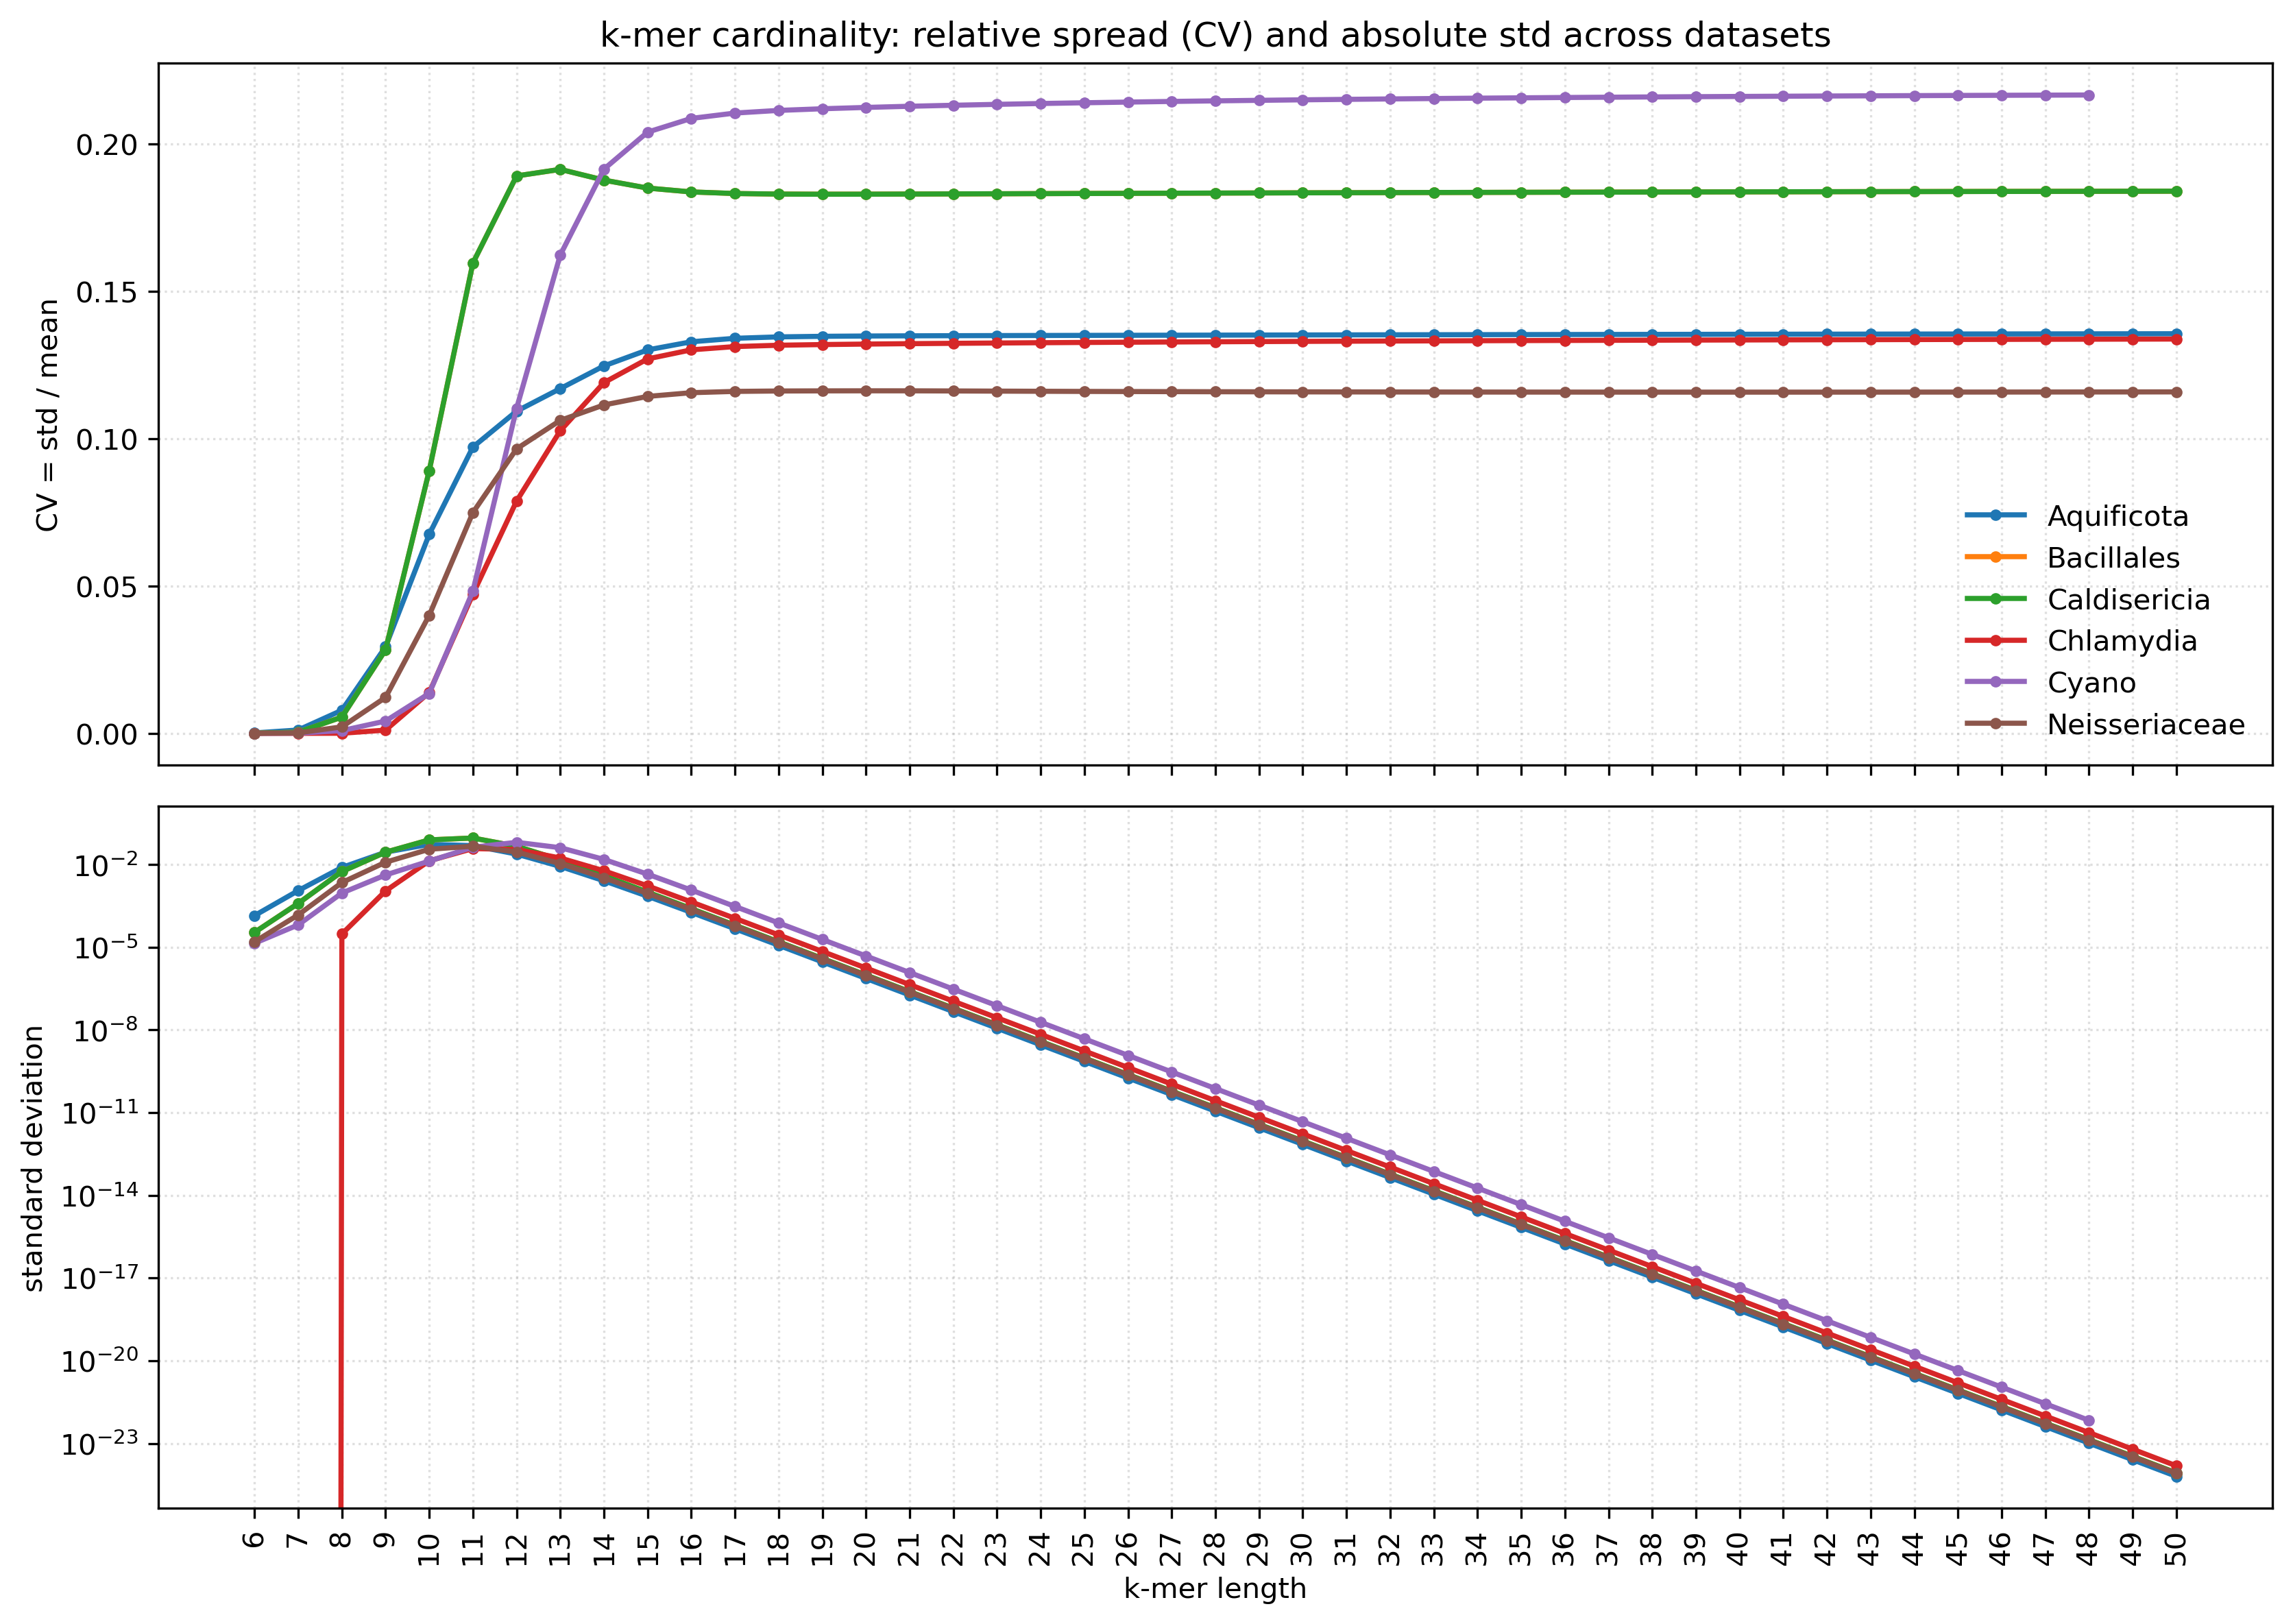

In [31]:
# Plot relative spread (CV = std / mean) and absolute std for all datasets.
# Top panel:    coefficient of variation = std / mean  (unitless, linear y-axis)
# Bottom panel: standard deviation                     (same units as cardinality, log y-axis)
# x-axis (shared): k-mer length

max_n_ks = max(len(df.columns) for df in dataset_kmer_stats.values())
fig, (ax_cv, ax_std) = plt.subplots(
    2, 1,
    figsize=(max(8, max_n_ks * 0.25), 8),
    sharex=True,
)

colors = plt.cm.get_cmap("tab10")
for idx, (name, stats_df) in enumerate(dataset_kmer_stats.items()):
    color = colors(idx % 10)
    ks = np.asarray(stats_df.columns, dtype=int)
    std = stats_df.loc["standard deviation"].to_numpy(dtype=float)
    mean = stats_df.loc["average"].to_numpy(dtype=float)

    with np.errstate(divide="ignore", invalid="ignore"):
        cv = np.where(mean > 0, std / mean, np.nan)

    ax_cv.plot(ks, cv, color=color, linewidth=1.8, marker="o", markersize=3, label=name)
    ax_std.plot(ks, std, color=color, linewidth=1.8, marker="o", markersize=3, label=name)

ax_cv.set_ylabel("CV = std / mean")
ax_cv.set_title("k-mer cardinality: relative spread (CV) and absolute std across datasets")
ax_cv.grid(True, which="both", linestyle=":", alpha=0.4)
ax_cv.legend(loc="best", frameon=False)

ax_std.set_yscale("log")
ax_std.set_xlabel("k-mer length")
ax_std.set_ylabel("standard deviation")
all_ks = np.unique(np.concatenate([np.asarray(df.columns, dtype=int) for df in dataset_kmer_stats.values()]))
ax_std.set_xticks(all_ks)
ax_std.tick_params(axis="x", rotation=90)
ax_std.grid(True, which="both", linestyle=":", alpha=0.4)

plt.tight_layout()
plt.show()


# Single-k recommendation from -log10 cardinality dynamics

Goal: recommend a single k-mer length per dataset using only the dynamics
(1st / 2nd derivative) of `-log10` k-mer cardinality `C(k)`, then compare to the
known single-best k from the full grid search.

`y(k) = -log10(C(k))` has three regimes:
- **saturated** (`k<=9`): `C~=1`, slope `~=0`
- **transition** (`k~=9-14`): slope ramps up, the 2nd derivative peaks (`k~=11-12`)
- **linear** (`k>=14`): slope is constant at `~=log10(4)=0.602`, because each
  genome's distinct k-mer count has stabilized and `C(k)~=G/(4**k/2)`

The known single-best k (19-24) lies *inside* the linear regime, a fixed offset
past its onset. So the raw elbow / constant-slope onset are good lower bounds but
undershoot; an onset + calibrated offset is the best derivative-only recommender.

Helpers live in `ok_k_mer_card_explore.py`.

In [ ]:
import importlib
import ok_k_mer_card_explore as ce
importlib.reload(ce)

# Load all per-dataset cardinality stats TSVs from the current directory.
card_stats = ce.load_all_kmer_stats(".")
print("Loaded datasets:", list(card_stats.keys()))
print("Known best k:", ce.KNOWN_BEST_K)

In [ ]:
# Per-dataset 3-panel dynamics: y = -log10(C(k)), 1st derivative, 2nd derivative.
# The red line marks the known single-best k.
for name, stats_df in card_stats.items():
    ce.plot_logcard_dynamics(name, stats_df, stat="average", smooth=True)
    plt.show()

In [ ]:
# Compare every derivative-based single-k estimator against the known optimum.
#   elbow_d2max        : k at max 2nd derivative (transition elbow)
#   slope_onset        : k where slope first reaches 95% of log10(4) (linear-regime onset)
#   transition_end     : k where 2nd derivative returns to ~0 after its peak
#   onset_plus_offset  : slope_onset + a constant offset calibrated on these datasets
estimator_table = ce.build_estimator_table(card_stats, stat="average", frac=0.95)
print("Calibrated onset->optimum offset:", estimator_table.attrs["calibrated_offset"])
estimator_table

### Takeaway

On these 6 datasets the pure derivative signals undershoot the optimum:
- `elbow_d2max` (~11-12) and `slope_onset` (~14-15) sit well below the true
  best k (19-24), with mean absolute error ~9 and ~6 respectively.
- `transition_end` (~16-17) is closer (MAE ~4) but still low.
- `slope_onset + offset` (offset ~6) is the best derivative-only recommender
  (MAE ~1.5), but the offset is empirically calibrated, not derived.

Interpretation: `-log10` union-cardinality dynamics pin down the *onset of the
linear (unsaturated) regime* as a robust lower bound, but the union-cardinality
summary saturates (slope, CV all go constant) exactly where the optimum lives,
so it cannot locate the optimum on its own. Signals that keep varying past
`k~=14` are explored below.

### Complementary signals to explore

The union-cardinality dynamics saturate near the optimum. Below we scaffold
other signals that may locate the optimum more directly:
1. relative-spread dynamics across pairs (CV, log-IQR) and their derivatives
2. a theoretical model `C(k) = min(1, G / (4**k / 2))` with fitted effective
   genome size `G`
3. overlaying the *actual* one-k Spearman correlation curve (from the grid
   search tensors) against the derivative features, to see where each feature
   lands relative to the true optimum

In [ ]:
# (1) Relative-spread dynamics across genome pairs.
# Unlike the mean, CV / log-IQR can keep evolving past the linear-regime onset.
for name, stats_df in card_stats.items():
    spread = ce.compute_spread_dynamics(stats_df)
    opt_k = ce.KNOWN_BEST_K.get(name)

    fig, (ax_cv, ax_iqr) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    ax_cv.plot(spread.index, spread["cv"], marker="o", ms=3, color="C0")
    ax_cv.set_ylabel("CV = std / mean")
    ax_iqr.plot(spread.index, spread["iqr_log"], marker="o", ms=3, color="C2")
    ax_iqr.set_ylabel("log-IQR  (-log10 Q1 minus -log10 Q3)")
    ax_iqr.set_xlabel("k-mer length")
    for ax_i in (ax_cv, ax_iqr):
        if opt_k is not None:
            ax_i.axvline(opt_k, color="C3", lw=1.5, label=f"known best k={opt_k}")
        ax_i.grid(True, ls=":", alpha=0.4)
        ax_i.legend(loc="best", frameon=False, fontsize=8)
    ax_cv.set_title(f"{name}: relative-spread dynamics")
    fig.tight_layout()
    plt.show()

In [ ]:
# (2) Theoretical model C(k) = min(1, G / (4**k / 2)); fit G from the linear tail.
rows = []
for name, stats_df in card_stats.items():
    G, slope, intercept = ce.fit_effective_genome_size(stats_df, k_fit_min=16)
    rows.append({"dataset": name, "effective_G": G,
                 "fit_slope": slope, "asymptote": ce.ASYMPTOTIC_SLOPE})
genome_size_table = pd.DataFrame(rows).set_index("dataset")
print(genome_size_table)

# Overlay observed vs theoretical -log10 C(k) for one example dataset.
example = next(iter(card_stats))
stats_df = card_stats[example]
G, _, _ = ce.fit_effective_genome_size(stats_df, k_fit_min=16)
deriv = ce.compute_logcard_derivatives(stats_df)
k = deriv["k"]
plt.figure(figsize=(8, 4))
plt.plot(k, deriv["y"], marker="o", ms=3, label="observed -log10 C(k)")
plt.plot(k, -np.log10(ce.theoretical_card(k, G)), ls="--",
         label=f"theoretical (G={G:,.0f})")
plt.xlabel("k-mer length"); plt.ylabel("-log10 C(k)")
plt.title(f"{example}: observed vs theoretical cardinality")
plt.legend(frameon=False); plt.grid(True, ls=":", alpha=0.4)
plt.tight_layout(); plt.show()

In [ ]:
# (3) Overlay the ACTUAL one-k Spearman correlation curve (grid-search tensor)
# against the -log10 cardinality derivatives, to see where each feature lands.
# Requires `datasets_1k` to be loaded (see the 1k load cell above).
try:
    onek_by_name = {name: np.abs(grid) for name, grid in datasets_1k}
except NameError:
    onek_by_name = {}
    print("datasets_1k not in scope; run the 1k-load cell first to enable overlay.")

for name, stats_df in card_stats.items():
    if name not in onek_by_name:
        continue
    grid = onek_by_name[name]            # columns: [k, |corr|, pval]
    grid_k = grid[:, 0].astype(int)
    grid_corr = grid[:, 1].astype(float)
    best_k = int(grid_k[np.nanargmax(grid_corr)])

    deriv = ce.compute_logcard_derivatives(stats_df)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(grid_k, grid_corr, color="C3", marker="o", ms=3,
            label="|Spearman corr| (one k)")
    ax.axvline(best_k, color="C3", ls="-", lw=1, alpha=0.6,
               label=f"grid argmax k={best_k}")
    ax.set_xlabel("k-mer length"); ax.set_ylabel("|Spearman corr|")

    ax2 = ax.twinx()
    ax2.plot(deriv["k"], deriv["d1"], color="C0", ls="--", label="d1 (-log10 C)")
    ax2.plot(deriv["k"], deriv["d2"], color="C2", ls=":", label="d2 (-log10 C)")
    ax2.set_ylabel("derivatives of -log10 C(k)")

    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(lines, [ln.get_label() for ln in lines], loc="lower right",
              frameon=False, fontsize=8)
    ax.set_title(f"{name}: one-k correlation vs cardinality derivatives")
    ax.grid(True, ls=":", alpha=0.4)
    fig.tight_layout(); plt.show()